# Imports and load data

## Import libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cmcrameri import cm
import os
import socket
from roaring_landmask import RoaringLandmask

# ------------------------------------------------------------
# Load mean IWC profile data
# ------------------------------------------------------------


In [5]:
# Helper
def describe(arr):
    return {
        "count": arr.size,
        "mean": np.mean(arr),
        "std": np.std(arr),
        "min": np.min(arr),
        "5%": np.percentile(arr, 5),
        "25%": np.percentile(arr, 25),
        "50%": np.percentile(arr, 50),
        "75%": np.percentile(arr, 75),
        "95%": np.percentile(arr, 95),
        "max": np.max(arr),
    }


## Load data (Only bulk_data_df important)

In [6]:
if socket.gethostname()=='iacmac-ds4990':
    BULK_PATH = "/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/02"
else:
    BULK_PATH = "/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics"
# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# iwc_rel_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2007.parquet"))
# iwc_rel_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2008.parquet"))
# mean_iwc_by_height_df = pd.read_parquet(os.path.join(BULK_PATH,"mean_iwc_by_height_data_V3_1_2007.parquet"))
# iwc_rel_df_loaded = pd.concat([iwc_rel_df_1, iwc_rel_df_2], ignore_index=True)

bulk_data_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
bulk_data_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2008.parquet"))
bulk_data_df_3 = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2009.parquet"))
bulk_data_df_4 = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2010.parquet"))
bulk_data_df = pd.concat([bulk_data_df_1, bulk_data_df_2,bulk_data_df_3, bulk_data_df_4], ignore_index=True)

# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# bulk_data_debug = pd.read_parquet(os.path.join("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/glaciations_with_bulk_data_V3_1_2007.parquet"))


In [7]:
bulk_data_df.iloc[25]["Z_bulk_means"][0]

array([-23.251865 , -20.41078  , -18.79381  , -18.02386  , -16.761087 ,
       -15.588446 , -14.911188 , -14.150634 , -13.368766 , -12.429618 ,
       -11.384511 , -10.3865795,  -9.348033 ,  -8.459352 ,  -7.642064 ,
        -6.993121 ,  -6.5603046,  -6.3077636], dtype=float32)

Filter rows with no measurements (Cehck why are there such???)

In [8]:
bulk_data_df=bulk_data_df[bulk_data_df.apply(lambda row: not (len(row["bulk_height_means_m"])==0) , axis=1)]

## Split cells by pass

In [9]:
ROWS_1D=["ddc_cloud_top_temp_means_K","ddc_cloud_top_height_means_m", "iwc_top_means", "colocation_time"]

In [10]:
import numpy as np
import pandas as pd


def is_pass_list(x):
    """
    True if x looks like a per-pass list/array:
    e.g. [pass1, pass2] where each pass may itself be a list/array.
    """
    if isinstance(x, np.ndarray):
        return isinstance(x[0], np.ndarray)

    return False


def split_rows_by_pass(df, reference_col="bulk_height_means_m"):
    new_rows = []

    for _, row in df.iterrows():
        ref_val = row[reference_col]

        # Number of passes, e.g. len([[...], [...]]) == 2
        if is_pass_list(ref_val):
            n_passes = len(ref_val)
        else:
            n_passes = 1
        for pass_i in range(n_passes):
            new_row = {}

            for col in df.columns:
                val = row[col]
                # If this column contains per-pass values, take the matching pass
                if is_pass_list(val):
                    if pass_i < len(val):
                        new_row[col] = val[pass_i]
                    else:
                        # Leave empty if this column does not have this pass
                        new_row[col] = np.nan
                elif col in ROWS_1D:
                    new_row[col] = val[pass_i]
                else:
                    # Scalar / non-list values are copied to every split row
                    new_row[col] = val
                


            new_rows.append(new_row)

    return pd.DataFrame(new_rows, columns=df.columns)

# row = 

bulk_data_df_split = split_rows_by_pass(
    bulk_data_df,
    reference_col="bulk_height_means_m"
)
bulk_data_df_split = bulk_data_df_split[(bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & ((bulk_data_df_split["avg_ctt"]-273.15)>-36))]
bulk_data_df_split


,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_height_means_m,ddc_cloud_top_height_means_m,ddc_cloud_top_temp_means_K,ext_bulk_means,temp_bulk_means,Z_bulk_means,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m,size_hist_km_debug
0,70032,75,0.716289,46,51,True,0.090226,"[0.5730308055877685, 0.5730308055877685, 0.573...",0.573031,1.25,...,"[6.514615, 6.481074, 6.3637276, 6.1866965, 5.8...",6.514615,237.852280,"[3.1734293e-05, 3.414293e-05, 3.5044148e-05, 3...","[237.85228, 238.24641, 239.17932, 240.26894, 2...","[-26.62337, -25.85598, -25.968014, -26.200325,...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
1,70408,105,0.425825,22,29,False,0.167923,"[0.03942757613745672, 0.040755974553597286, 0....",0.303342,1.75,...,"[4.3713665, 4.290206, 4.134128, 3.9109821, 3.4...",4.371367,259.799683,"[6.136837e-05, 6.236592e-05, 5.5882938e-05, 3....","[259.79968, 259.86838, 260.40674, 261.48206, 2...","[-22.21927, -20.380392, -20.995928, -22.083258...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
2,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,"[4.298905, 4.1822667, 4.063569, 3.9442232, 3.8...",4.298905,258.880188,"[0.0020007854, 0.0030006275, 0.003652379, 0.00...","[258.8802, 259.44913, 259.94424, 260.39053, 26...","[-15.76357, -12.826077, -10.580673, -8.728764,...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
3,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[2.9155383, 3.06, 2.9423077, 2.8223078, 2.2160...",2.915538,257.667480,"[6.4273727e-06, 9.508473e-06, 1.4556285e-05, 1...","[257.66748, 256.61264, 257.30948, 257.98065, 2...","[-30.644104, -28.91097, -28.187925, -27.067188...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
4,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[2.8150923, 2.5814378, 2.3589048, 2.2378335, 2...",2.815092,258.123444,"[0.0015020855, 0.00096732663, 0.000519377, 0.0...","[258.12344, 259.4614, 260.59402, 261.16345, 26...","[-29.973204, -29.222662, -29.148697, -29.16398...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6208,3016459,240,0.606988,74,90,True,0.111645,"[0.15174710750579834, 0.15174710750579834, 0.1...",0.151747,4.00,...,"[5.991854, 5.7793727, 5.6632557, 5.48973, 5.14...",5.991854,239.861099,"[0.00029364842, 0.00045937902, 0.0006604842, 0...","[239.8611, 241.19537, 241.9347, 243.02045, 245...","[-12.93491, -9.255584, -6.7351446, -5.5270214,...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[1793.2035, 8213.481, 11518.956, 16209.534, 16..."
6209,3016673,465,0.463811,7,38,False,0.185686,"[0.028236934379587453, 0.028983981285186203, 0...",0.151408,7.75,...,"[4.220588, 4.05948, 3.9440336, 3.8213692, 3.70...",4.220588,242.489319,"[3.1700702e-06, 1.0954542e-05, 2.7391176e-05, ...","[242.48932, 243.28241, 243.87073, 244.48207, 2...","[-28.60748, -26.91344, -24.81283, -23.192513, ...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[1233.3076, 2459.7646, 2452.637, 4656.4097, 53..."
6210,3016857,240,0.430335,100,116,True,0

In [11]:
((bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & (bulk_data_df_split["avg_ctt"]-273.15)>-36)).value_counts()

avg_ctt
True    6031
Name: count, dtype: int64

In [12]:
test_row=bulk_data_df_split.iloc[0]

## Stats by relative time

In [13]:
ORIGINAL_VALID_CLOUD_COLUMNS = bulk_data_df.columns.tolist()

bulk_data_df_split["rel_ind"] = bulk_data_df_split.apply(
    lambda row: int(round(
        (pd.Timestamp(row["colocation_time"]) - row["track_start_time"]) / pd.Timedelta(minutes=15)
    )) - int(row["Glac_peak_ind"]),
    axis=1
)
bulk_data_df_split["rel_time_min"] = bulk_data_df_split["rel_ind"]*15
sample = bulk_data_df_split.sample(100, random_state=1)

In [14]:
def generate_stats_by_rel_time(df, mode="mean"):
    if mode == "mean":
        stats_by_rel_time = (
            df
            .groupby("rel_ind")
            .agg(
                n_hits=("iwc_bulk_means", "count"),

                mean_iwc_profile=(
                    "iwc_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_Z_profile=(
                    "Z_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_ext_profile=(
                    "ext_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_temp_profile=(
                    "temp_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                mean_bulk_height_profile_m=(
                    "bulk_level_offset_mid_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_top_m=(
                    "bulk_level_offset_top_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_bottom_m=(
                    "bulk_level_offset_bottom_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                dd_cth=(
                    "ddc_cloud_top_height_means_m",
                    "mean",
                ),

                sev_cth=(
                    "avg_cth",
                    "mean",
                ),

                dd_ctt=(
                    "ddc_cloud_top_temp_means_K",
                    "mean",
                ),

                mean_iwc_ct=(
                    "iwc_top_means",
                    "mean",
                ),

                sev_ctt=(
                    "avg_ctt",
                    "mean",
                ),
                
                mean_area_km=(
                    "avg_size[km]",
                    "mean",
                ),
                
            )
            .reset_index()
        )
    elif mode=="median":
        print("Calculating median")
        stats_by_rel_time = (
        df
        .groupby("rel_ind")
        .agg(
            n_hits=("iwc_bulk_means", "count"),

            mean_iwc_profile=(
                "iwc_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_Z_profile=(
                "Z_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_ext_profile=(
                "ext_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_temp_profile=(
                "temp_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            mean_bulk_height_profile_m=(
                "bulk_level_offset_mid_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_top_m=(
                "bulk_level_offset_top_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_bottom_m=(
                "bulk_level_offset_bottom_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            dd_cth=(
                "ddc_cloud_top_height_means_m",
                "median",
            ),

            sev_cth=(
                "avg_cth",
                "median",
            ),

            dd_ctt=(
                "ddc_cloud_top_temp_means_K",
                "median",
            ),

            mean_iwc_ct=(
                "iwc_top_means",
                "median",
            ),


            sev_ctt=(
                "avg_ctt",
                "median",
            ),
            
            mean_area_km=(
                "avg_size[km]",
                "median",
            ),
            
            )
            .reset_index()
        )
    else:
        raise ValueError("Set statistics 'MODE' to mean or median")
    stats_by_rel_time["rel_time_min"] = stats_by_rel_time["rel_ind"] * 15
    return stats_by_rel_time

# Optical depth statistics

In [15]:
def calculate_top_depth(row):
    tot_thickness = 0
    small_ext_counter = 0
    for j, ext in enumerate(row["ext_bulk_means"]):
        lev_depth = row.bulk_level_offset_top_m[j]-row.bulk_level_offset_bottom_m[j]
        tot_thickness += lev_depth*ext
        if ext<2.0e-4:
            small_ext_counter+=1
        if tot_thickness>=0.3:
            # print(tot_thickness,j*120,small_ext_counter*120)
            return j*120
    return None
        
            
sample["ct_depth"] = sample.apply(calculate_top_depth,axis=1)

In [16]:
(sample["ct_depth"]>600).value_counts()

ct_depth
False    64
True     36
Name: count, dtype: int64

In [17]:
def optical_depth_path(row):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    # optional safety check
    if len(dz) != len(ext):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, extinction has {len(ext)} values"
        )

    tau_path = [0.0]
    depth_path = [0.0]

    tau = 0.0
    depth = 0.0

    for layer_dz, layer_ext in zip(dz, ext):
        layer_tau = layer_dz * layer_ext

        tau += layer_tau
        depth += layer_dz

        tau_path.append(tau)
        depth_path.append(depth)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path)
    }

def calculate_ct_depth(row, cod_threshold=0.3):
    tau = optical_depth_path(bulk_data_filtered.iloc[0])["tau"]>0.3
    top_idx = np.argmax(tau>cod_threshold)
    if top_idx==0 and tau[-1]<cod_threshold:
        return np.nan
    else: return top_idx*120

In [18]:
# Calculate total optical depth per cloud 
bulk_data_df_split["2km_cot"] = bulk_data_df_split.apply(lambda row: optical_depth_path(row)["tau"][-1], axis=1)
bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: ((optical_depth_path(row)["tau"][1:]-optical_depth_path(row)["tau"][:-1])>5*1e-4).all(), axis=1)
bulk_data_df_split["ct_depth"]=bulk_data_df_split.apply(calculate_top_depth,axis=1)

In [19]:
# print(np.argmax(optical_depth_path(bulk_data_filtered.iloc[0])["tau"]>0.3))
# print(optical_depth_path(bulk_data_filtered.iloc[0])["tau"])

<Figure size 700x500 with 0 Axes>

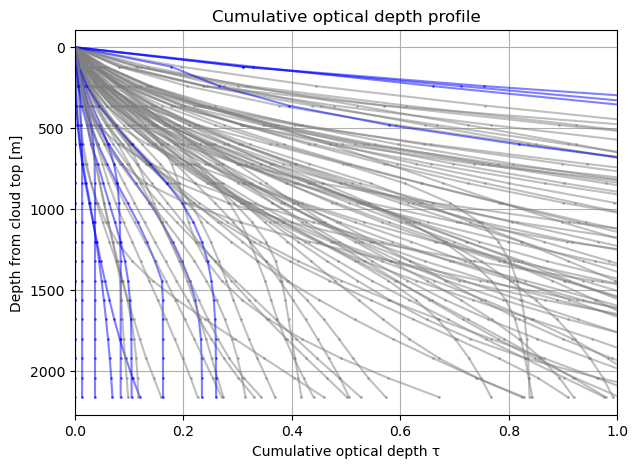

In [20]:
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import matplotlib.pyplot as plt




plt.figure(figsize=(7, 5))

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path(row)

    if p is None:
        continue
    if ((p["tau"][1:]-p["tau"][:-1])<5*1e-4).any():
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="blue",
            markersize=1
        )
    else:
        plt.plot(
            p["tau"],
            p["depth_m"],
            alpha=0.5,
            marker="o",
            color="gray",
            markersize=1
        )



# plt.axvline(0.2, linestyle="--", linewidth=1, label="τ = 0.2")

plt.xlabel("Cumulative optical depth τ")
plt.ylabel("Depth from cloud top [m]")
plt.title("Cumulative optical depth profile")
plt.grid(True)
plt.xlim(0, 1)

# Optional: depth increasing downward
plt.gca().invert_yaxis()

plt.show()

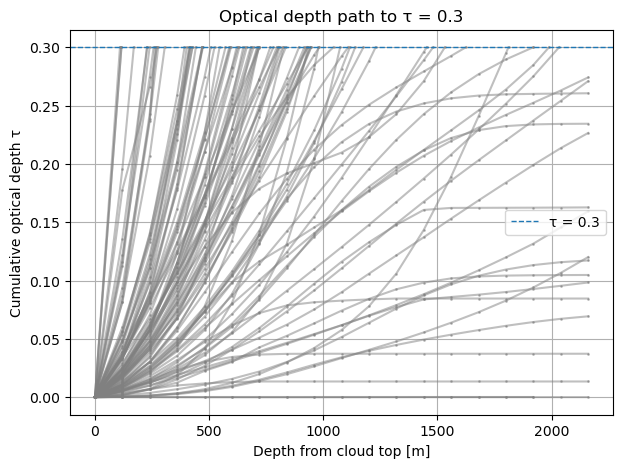

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt

def optical_depth_path_to_03(row, tau_target=0.3):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext_profile = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    if len(dz) != len(ext_profile):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, "
            f"extinction has {len(ext_profile)} values"
        )

    tau = 0.0
    depth = 0.0

    depth_path = [0.0]
    tau_path = [0.0]

    for layer_dz, ext in zip(dz, ext_profile):
        layer_tau = layer_dz * ext

        # if tau_target is reached inside this layer, interpolate
        if tau + layer_tau >= tau_target:
            remaining_tau = tau_target - tau

            if ext > 0:
                depth_inside_layer = remaining_tau / ext
            else:
                depth_inside_layer = layer_dz

            depth += depth_inside_layer
            tau = tau_target

            depth_path.append(depth)
            tau_path.append(tau)
            break

        tau += layer_tau
        depth += layer_dz

        depth_path.append(depth)
        tau_path.append(tau)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path),
        "reached_03": tau >= tau_target
    }

plt.figure(figsize=(7, 5))

for row_idx, row in sample.iterrows():
    p = optical_depth_path_to_03(row, tau_target=0.3)

    if p is None:
        continue

    plt.plot(
        p["depth_m"],
        p["tau"],
        alpha=0.5,
        marker="o",
        color="gray",
        markersize=1
    )

plt.axhline(0.3, linestyle="--", linewidth=1, label="τ = 0.3")

plt.xlabel("Depth from cloud top [m]")
plt.ylabel("Cumulative optical depth τ")
plt.title("Optical depth path to τ = 0.3")
plt.grid(True)
plt.legend()
plt.show()

# Z statistics

## Filter data 

In [22]:
landmask = RoaringLandmask.new()
def classify_surface(lats, lons):
    """
    lats, lons: arrays in degrees
    returns: array of 'maritime' or 'land'
    """
    is_land = np.array([
        landmask.contains(lon, lat)
        for lat, lon in zip(lats, lons)
    ])

    return np.where(is_land, "land", "maritime")


bulk_data_df_split["surface_type"] = bulk_data_df_split.apply(lambda row: classify_surface(
    row["lat_hist"],
    row["lat_hist"]
),axis=1)
bulk_data_df_split["is_maritime"] = bulk_data_df_split.apply(lambda row: (row["surface_type"]=="maritime").mean()>=1, axis=1)

In [139]:
# Filter only for clouds that survive after glaciation
bulk_data_filtered = bulk_data_df_split[bulk_data_df_split.track_length / pd.Timedelta(minutes=15) > bulk_data_df_split["Glac_peak_ind"]]
# Filter for cloud lifetime - not too long
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.track_length < pd.Timedelta(hours=12)]

# Filter for significant bulk optical thickness
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["2km_cot"]>0.3]
# Select only one pass where 2 are available
# bulk_data_filtered = bulk_data_filtered.drop_duplicates(subset="Cloud_ID", keep="first")
# Filter for cclouds where extinction doesn't drop in the 2 kilometers
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["continious_cloud"]]
# Filter for cloud type
bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Altostratus", "Nimbostratus", "Stratocumulus", "Stratus"])]
# Remove clouds outside measurement boundaries
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 < 0]
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 > -36]
# Take only maritime clouds
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["is_maritime"]]
bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Hemisphere"]=="South"]
stats_by_rel_time = generate_stats_by_rel_time(bulk_data_filtered, mode="mean")
bulk_data_filtered

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_level_offset_bottom_m,bulk_level_offset_mid_m,size_hist_km_debug,rel_ind,rel_time_min,2km_cot,continious_cloud,ct_depth,surface_type,is_maritime
2,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,35,525,8.094050,True,120.0,"[maritime, maritime, maritime, maritime, marit...",True
4,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,82,1230,1.307791,True,240.0,"[maritime, maritime, maritime, maritime, marit...",True
6,74600,75,1.000000,20,25,False,0.147536,"[0.7355483057504995, 1.2362305155394049, 1.236...",0.813812,1.25,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,-17,-255,2.602609,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
10,106589,60,0.521698,63,67,False,0.142036,"[0.3393176823442888, 0.5477031707440038, 0.640...",0.469096,1.00,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,-53,-795,0.792862,True,1320.0,"[maritime, maritime, maritime, maritime, marit...",True
11,106589,60,0.521698,63,67,False,0.142036,"[0.3393176823442888, 0.5477031707440038, 0.640...",0.469096,1.00,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,-14,-210,0.360333,True,1920.0,"[maritime, maritime, maritime, maritime, marit...",True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6188,3009831,360,0.491177,0,24,True,0.085614,"[0.08186286687850952, 0.08186286687850952, 0.0...",0.081863,6.00,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[5267.317, 13232.3, 21364.246, 30868.326, 2482...",-11,-165,4.881477,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
6190,3009920,60,0.567205,0,4,True,0.057134,"[0.5672049522399902, 0.5672049522399902, 0.567...",0.567205,1.00,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[2498.5864, 2784.3418, 3622.0881, 3077.7827, 2...",1,15,5.043656,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
6206,3016057,135,0.558380,17,26,True,0.044564,"[0.24816907776726616, 0.24816907776726616, 0.2...",0.248169,2.25,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[2636.0208, 2640.2153, 5653.9463, 8651.206, 11...",-9,-135,1.399332,True,1080.0,"[maritime, maritime, maritime, maritime, marit...",True
6207,3016459,135,0.498311,8,17,True,0.073970,"[0.22147133615281847, 0.22147133615281847, 0.2...",0.221471,2.25,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[1793.2035, 8213.481, 11518.956, 16209.534, 16...",26,390,4.776647,True,480.0,"[maritime, maritime, maritime, maritime, marit...",True


## Extract Bulk

In [140]:
(bulk_data_df["track_length"] / pd.Timedelta(minutes=15)>bulk_data_df["Glac_peak_ind"]).value_counts(normalize=True)

True     0.805883
False    0.194117
Name: proportion, dtype: float64

In [141]:
(bulk_data_filtered["Glaciation time [h]"] < 3).value_counts(normalize=True)

Glaciation time [h]
False    0.620625
True     0.379375
Name: proportion, dtype: float64

In [142]:
test_row.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'val_ice_frac_hist', 'val_ice_frac_std_hist', 'val_ice_frac_dev_hist',
       'val_pix_claas_if_hist', 'val_pix_claas_if_std_hist', 'val_cth_hist',
    

In [143]:
def extract_lag_if(row,lag):
    ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))-lag
    if ind < len(row["ice_frac_hist"]) and ind>=0:
        return row["ice_frac_hist"][ind] 
    else:
        return np.nan

In [144]:
if_bins=np.arange(0,1.1,0.1)
Z_meas_lag_if = {}
t_meas_lag_if={}
ext_meas_lag_if={}
for lag in range(-4,5):
    col = f"IF_lag_{lag}"
    bulk_data_filtered[f"IF_lag_{lag}"] = bulk_data_filtered.apply(extract_lag_if,axis=1,args=(lag,))
    # Bin it in 0.1 width from 0 to 1 including boundaries
    # bulk_data_filtered[f"IF_lag_{lag}"]
    Z_meas_lag_if[lag] = {}
    t_meas_lag_if[lag] = {}
    ext_meas_lag_if[lag] = {}
    # Iterate over bins: [0.4,0.5), [0.5,0.6), ..., [0.9,1.0]
    for low, high in zip(if_bins[:-1], if_bins[1:]):
        if high == if_bins[-1]:
            mask = (bulk_data_filtered[col] >= low) & (bulk_data_filtered[col] <= high)
        else:
            mask = (bulk_data_filtered[col] >= low) & (bulk_data_filtered[col] < high)
        values_Z = bulk_data_filtered.loc[mask, "Z_bulk_means"].to_numpy()
        values_t = bulk_data_filtered.loc[mask, "temp_bulk_means"].to_numpy()
        values_ext = bulk_data_filtered.loc[mask, "ct_depth"].to_numpy()

        if len(values_Z) > 0:
            Z_meas_lag_if[lag][low] = np.vstack(values_Z)
            t_meas_lag_if[lag][low] = np.vstack(values_t)
            t_meas_lag_if[lag][low] = np.vstack(values_ext)
        else:
            Z_meas_lag_if[lag][low] = np.empty((0,))

In [145]:
bulk_data_filtered["IF_change"] = (bulk_data_filtered[f"IF_lag_1"] - bulk_data_filtered[f"IF_lag_3"])/2

In [146]:
test_row["Z_bulk_means"]

array([-26.62337   , -25.85598   , -25.968014  , -26.200325  ,
       -26.562946  , -27.24948   , -26.38162   , -26.831804  ,
       -26.586681  , -26.85272   , -27.03771   , -24.84828   ,
       -25.50056   , -17.444578  ,  -8.271665  ,   0.85464174,
        11.175353  ,  21.228378  ], dtype=float32)

In [147]:
bulk_data_filtered["integrated_reflecticity"] = bulk_data_filtered.apply(lambda row: row["Z_bulk_means"][2:].sum(), axis=1)

In [148]:
bulk_data_filtered["ct_depth"]//120

2        1.0
4        2.0
6        3.0
10      11.0
11      16.0
        ... 
6188     3.0
6190     3.0
6206     9.0
6207     4.0
6211     9.0
Name: ct_depth, Length: 1600, dtype: float64

In [149]:
def extract_bulk_samples_by_time(df):
    Z_meas = {}
    t_meas = {}
    ext_meas = {}
    for rel_ind in np.sort(df.rel_ind.unique()):
        Z_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["Z_bulk_means"].to_numpy())
        t_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["temp_bulk_means"].to_numpy())
        ext_meas[rel_ind]=df[df["rel_ind"]==rel_ind]["ct_depth"].to_numpy()
    return Z_meas, t_meas, ext_meas

# def extract_bulk_samples_by_IF(df):
#     Z_meas = {}
#     t_meas = {}
#     ext_meas = {}
#     for rel_ind in range():
#         Z_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["Z_bulk_means"].to_numpy())
#         t_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["temp_bulk_means"].to_numpy())
#         ext_meas[rel_ind]=df[df["rel_ind"]==rel_ind]["ct_depth"].to_numpy()
#     return Z_meas, t_meas, ext_meas

Z_meas, t_meas, ext_meas = extract_bulk_samples_by_time(bulk_data_filtered)

In [150]:
# bulk_data_filtered["bulk_reflecticity"] = bulk_data_filtered.apply(lambda row: row["Z_bulk_means"][int(row["ct_depth"])//120:].mean(), axis=1)

In [151]:
# bulk_data_filtered["Z_anomaly"] = bulk_data_filtered.apply(lambda row: row["Z_bulk_means"] - level_mean, axis=1)

In [152]:
# bulk_data_filtered["bulk_anomaly"] = bulk_data_filtered.apply(lambda row: row["Z_anomaly"][int(row["ct_depth"])//120:].mean(), axis=1)
# bulk_data_filtered["integrated_anomaly"] = bulk_data_filtered.apply(lambda row: row["Z_anomaly"][2:].sum(), axis=1)

In [153]:
# print(bulk_data_filtered["bulk_reflecticity"].corr(bulk_data_filtered["IF_change"]))
# print(bulk_data_filtered["integrated_reflecticity"].corr(bulk_data_filtered["IF_change"]))
# print(bulk_data_filtered["bulk_anomaly"].corr(bulk_data_filtered["IF_change"]))
# print(bulk_data_filtered["integrated_anomaly"].corr(bulk_data_filtered["IF_change"]))


In [154]:
# print(bulk_data_filtered["bulk_reflecticity"].corr(bulk_data_filtered["IF_lag_1"]))
# print(bulk_data_filtered["integrated_reflecticity"].corr(bulk_data_filtered["IF_lag_1"]))
# print(bulk_data_filtered["bulk_anomaly"].corr(bulk_data_filtered["IF_lag_1"]))
# print(bulk_data_filtered["integrated_anomaly"].corr(bulk_data_filtered["IF_lag_1"]))

In [155]:
# print(bulk_data_filtered["bulk_reflecticity"].corr(bulk_data_filtered["IF_lag_1"]))
# print(bulk_data_filtered["integrated_reflecticity"].corr(bulk_data_filtered["IF_lag_1"]))
# print(bulk_data_filtered["bulk_anomaly"].corr(bulk_data_filtered["IF_lag_1"]))
# print(bulk_data_filtered["integrated_anomaly"].corr(bulk_data_filtered["IF_lag_1"]))

level_mean shape: (18,)


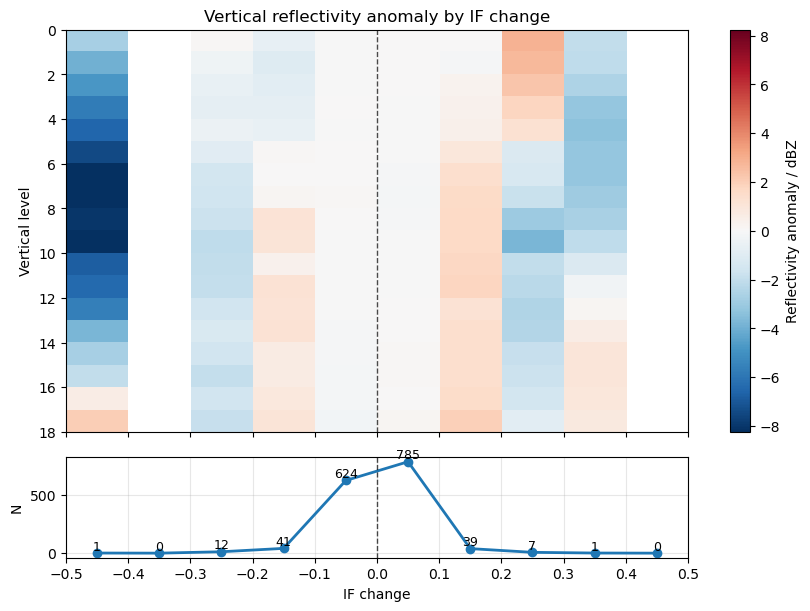

In [156]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec


# ------------------------------------------------------------
# 1. Outlier remover
# ------------------------------------------------------------
def remove_outliers_iqr(x, k=1.5):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 4:
        return x

    q1, q3 = np.nanpercentile(x, [25, 75])
    iqr = q3 - q1

    if iqr == 0 or not np.isfinite(iqr):
        return x

    lower = q1 - k * iqr
    upper = q3 + k * iqr

    return x[(x >= lower) & (x <= upper)]


# ------------------------------------------------------------
# 2. Mean profile with IQR outlier removal per vertical level
# ------------------------------------------------------------
def mean_profile_iqr(Z_stack, k=1.5):
    Z_stack = np.asarray(Z_stack, dtype=float)

    if Z_stack.size == 0:
        return None

    if Z_stack.ndim == 1:
        Z_stack = Z_stack[None, :]

    n_levels = Z_stack.shape[1]
    mean_profile = np.full(n_levels, np.nan)

    for lev in range(n_levels):
        x_clean = remove_outliers_iqr(Z_stack[:, lev], k=k)

        if len(x_clean) > 0:
            mean_profile[lev] = np.nanmean(x_clean)

    return mean_profile


# ------------------------------------------------------------
# 3. Compute IF_change
# ------------------------------------------------------------
bulk_data_filtered["IF_lag_1"] = bulk_data_filtered.apply(
    extract_lag_if,
    axis=1,
    args=(1,)
)

bulk_data_filtered["IF_lag_3"] = bulk_data_filtered.apply(
    extract_lag_if,
    axis=1,
    args=(3,)
)



# ------------------------------------------------------------
# 4. Bin by IF_change
# ------------------------------------------------------------
if_change_bins = np.arange(-0.5, 0.55, 0.1)

Z_meas_if_change = {}

for low, high in zip(if_change_bins[:-1], if_change_bins[1:]):

    if high == if_change_bins[-1]:
        mask = (
            (bulk_data_filtered["IF_change"] >= low)
            & (bulk_data_filtered["IF_change"] <= high)
        )
    else:
        mask = (
            (bulk_data_filtered["IF_change"] >= low)
            & (bulk_data_filtered["IF_change"] < high)
        )

    values_Z = bulk_data_filtered.loc[mask, "Z_bulk_means"].to_numpy()

    if len(values_Z) > 0:
        Z_meas_if_change[low] = np.vstack(values_Z)
    else:
        Z_meas_if_change[low] = np.empty((0,))


# ------------------------------------------------------------
# 5. Compute global level mean from all IF_change-bin samples
# ------------------------------------------------------------
all_samples = []

for arr in Z_meas_if_change.values():
    arr = np.asarray(arr, dtype=float)

    if arr.size == 0:
        continue

    if arr.ndim == 1:
        arr = arr[None, :]

    all_samples.append(arr)

all_samples = np.vstack(all_samples)

iqr_k = 1.5
level_mean = mean_profile_iqr(all_samples, k=iqr_k)

print("level_mean shape:", level_mean.shape)


# ------------------------------------------------------------
# 6. Compute anomaly heatmap and sample counts
# ------------------------------------------------------------
bins = np.asarray(sorted(Z_meas_if_change.keys()), dtype=float)
profiles = []
counts = []

for low in bins:
    Z_stack = Z_meas_if_change[low]

    if Z_stack.size == 0:
        counts.append(0)
        profiles.append(None)
        continue

    if Z_stack.ndim == 1:
        Z_stack = Z_stack[None, :]

    counts.append(Z_stack.shape[0])

    mean_profile = mean_profile_iqr(Z_stack, k=iqr_k)

    if mean_profile is None:
        profiles.append(None)
        continue

    anomaly_profile = mean_profile - level_mean
    profiles.append(anomaly_profile)


# Fill empty bins with NaNs
n_levels = next(p.size for p in profiles if p is not None)

profiles = [
    p if p is not None else np.full(n_levels, np.nan)
    for p in profiles
]

heatmap = np.column_stack(profiles)
counts = np.asarray(counts)


# ------------------------------------------------------------
# 7. Color scale
# ------------------------------------------------------------
vals = heatmap[np.isfinite(heatmap)]
absmax = np.nanpercentile(np.abs(vals), 99)

vmin, vmax = -absmax, absmax


# ------------------------------------------------------------
# 8. Plot heatmap + sample-count line graph below
# ------------------------------------------------------------
bin_width = np.nanmedian(np.diff(bins))
bin_centers = bins + bin_width / 2

x0 = bins[0]
x1 = bins[-1] + bin_width

fig = plt.figure(figsize=(8, 6), constrained_layout=True)

gs = GridSpec(
    2,
    1,
    height_ratios=[4, 1],
    figure=fig
)

ax_hm = fig.add_subplot(gs[0])
ax_n = fig.add_subplot(gs[1], sharex=ax_hm)


# ------------------------------------------------------------
# Heatmap
# ------------------------------------------------------------
im = ax_hm.imshow(
    heatmap,
    aspect="auto",
    origin="upper",
    cmap="RdBu_r",
    vmin=vmin,
    vmax=vmax,
    extent=[x0, x1, heatmap.shape[0], 0]
)

ax_hm.set_ylabel("Vertical level")
ax_hm.set_title("Vertical reflectivity anomaly by IF change")
ax_hm.axvline(0, color="k", linewidth=1, linestyle="--", alpha=0.7)

cbar = fig.colorbar(im, ax=ax_hm)
cbar.set_label("Reflectivity anomaly / dBZ")

# Hide x tick labels on heatmap, because lower panel has them
ax_hm.tick_params(labelbottom=False)


# ------------------------------------------------------------
# Sample-count line graph
# ------------------------------------------------------------
ax_n.plot(
    bin_centers,
    counts,
    marker="o",
    linewidth=2
)

for x, y in zip(bin_centers, counts):
    ax_n.text(
        x, y,
        str(int(y)),
        ha="center",
        va="bottom",
        fontsize=9
    )

ax_n.axvline(0, color="k", linewidth=1, linestyle="--", alpha=0.7)
ax_n.set_xlabel("IF change")
ax_n.set_ylabel("N")
ax_n.set_xlim(x0, x1)
ax_n.set_xticks(np.arange(x0, x1 + 1e-9, 0.1))
ax_n.grid(True, alpha=0.3)

-4 0
-3 1
-2 2
-1 3
0 4
1 5
2 6
3 7
4 8


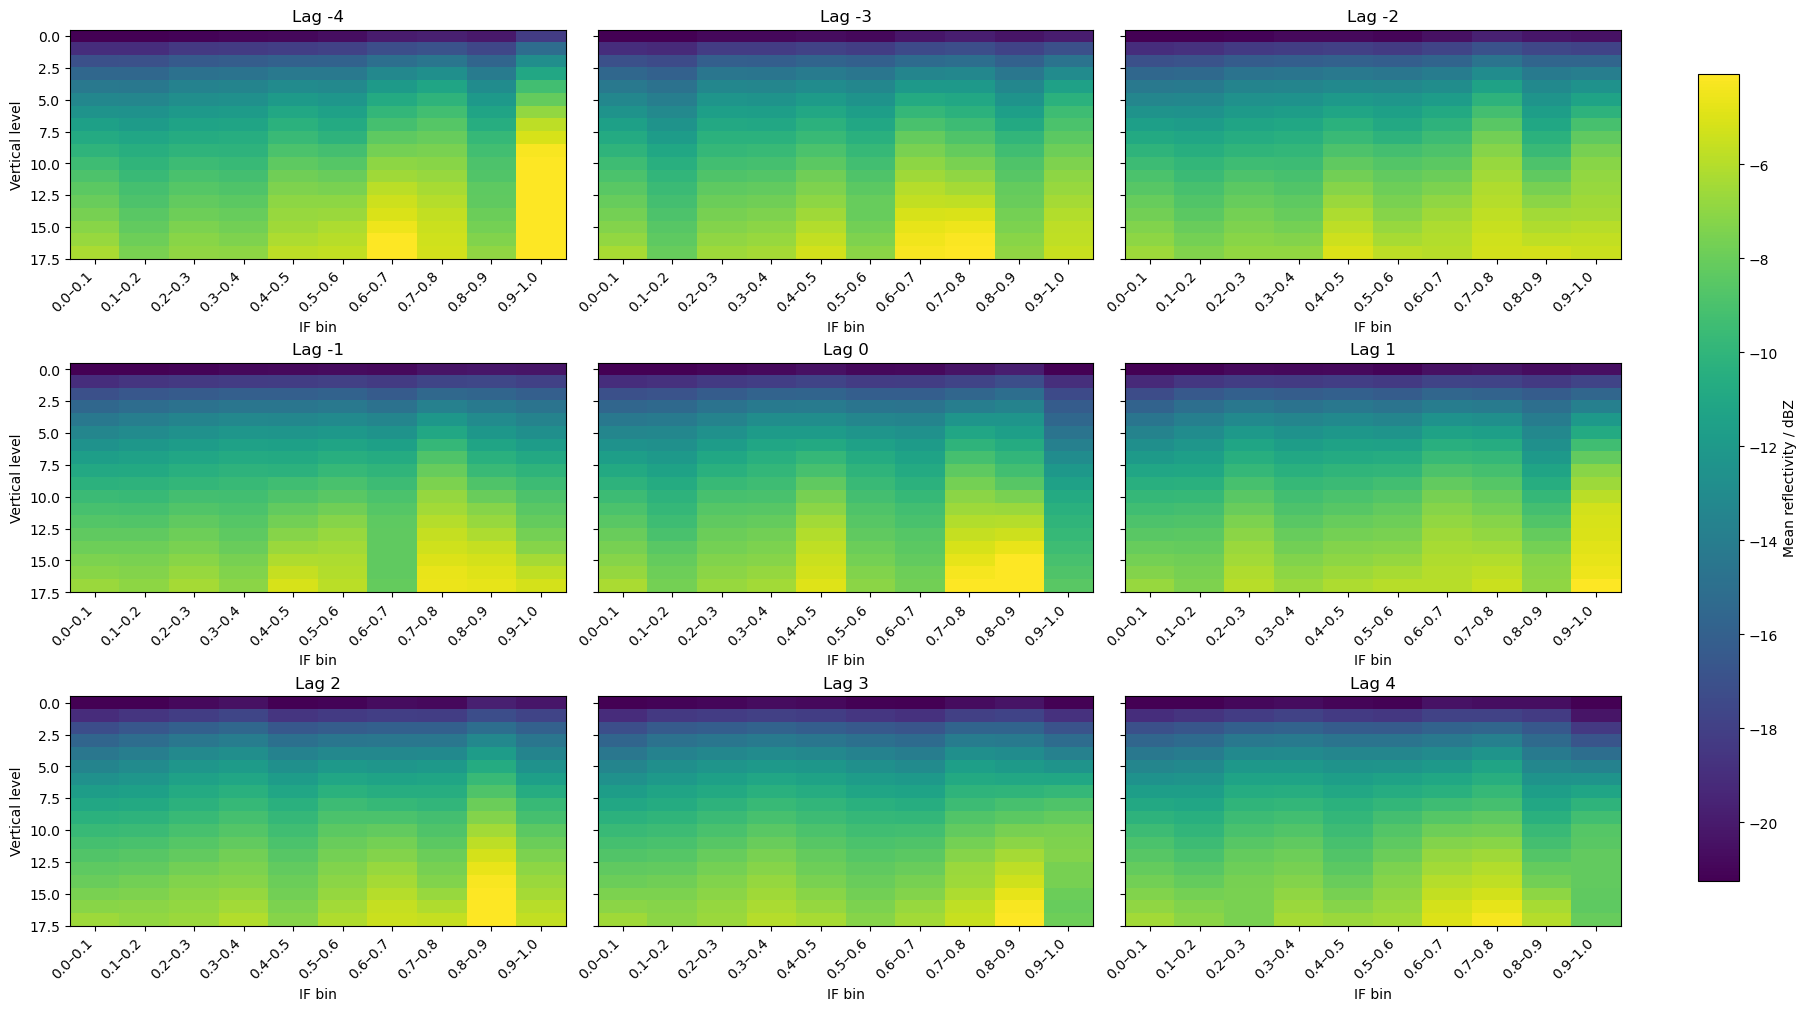

In [157]:
import numpy as np
import matplotlib.pyplot as plt

n_lags = len(Z_meas_lag_if)

fig, axes = plt.subplots(
    3, n_lags//3,
    figsize=(2 * n_lags, 10),
    sharey=True,
    constrained_layout=True
)

if n_lags == 1:
    axes = [axes]

# Common color scale across all lags
all_vals = []

for lag in sorted(Z_meas_lag_if.keys()):
    for if_bin, Z_stack in Z_meas_lag_if[lag].items():
        if Z_stack.size == 0:
            continue

        prof = np.nanmean(Z_stack, axis=0)
        all_vals.append(prof)

all_vals = np.concatenate(all_vals)
vmin, vmax = np.nanpercentile(all_vals, [1, 99])
heatmap=np.empty((18,10,n_lags))
i=0
row_ids = [0, n_lags//3, n_lags//3*2,n_lags]
for ax_row_id, ax_row in enumerate(axes):
    for ax, lag in zip(ax_row, sorted(Z_meas_lag_if.keys())[row_ids[ax_row_id]:row_ids[ax_row_id+1]]):

        bins = sorted(Z_meas_lag_if[lag].keys())
        profiles = []

        for if_bin in bins:
            Z_stack = Z_meas_lag_if[lag][if_bin]

            if Z_stack.size == 0:
                profiles.append(None)
                continue

            mean_profile = np.nanmean(Z_stack, axis=0)
            profiles.append(mean_profile)

        # Fill empty bins with NaNs of correct length
        n_levels = next(p.size for p in profiles if p is not None)

        profiles = [
            p if p is not None else np.full(n_levels, np.nan)
            for p in profiles
        ]

        # Shape: n_levels x n_bins
        heatmap[:,:,i] = np.column_stack(profiles)

        im = ax.imshow(
            heatmap[:,:,i],
            aspect="auto",
            origin="upper",
            vmin=vmin,
            vmax=vmax,
            cmap="viridis"
        )

        ax.set_title(f"Lag {lag}")
        ax.set_xlabel("IF bin")
        ax.set_xticks(np.arange(len(bins)))
        ax.set_xticklabels(
            [f"{b:.1f}–{b + 0.1:.1f}" for b in bins],
            rotation=45,
            ha="right"
        )
        print(lag,i)
        i+=1

for ax in axes[:,0]:
 ax.set_ylabel("Vertical level")

cbar = fig.colorbar(im, ax=axes, shrink=0.9)
cbar.set_label("Mean reflectivity / dBZ")

plt.show()

Global level mean shape: (18,)


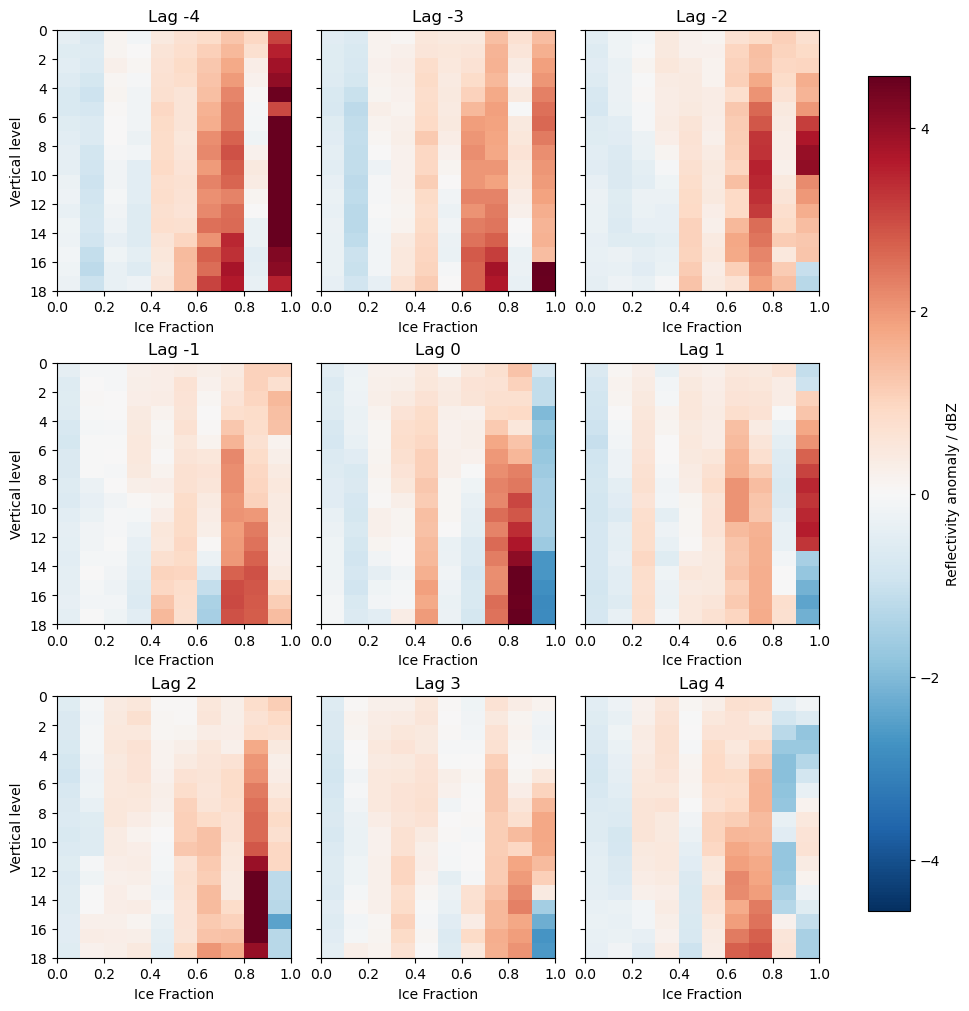

In [158]:
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Outlier remover
# ------------------------------------------------------------
def remove_outliers_iqr(x, k=1.5):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 4:
        return x

    q1, q3 = np.nanpercentile(x, [25, 75])
    iqr = q3 - q1

    if iqr == 0 or not np.isfinite(iqr):
        return x

    lower = q1 - k * iqr
    upper = q3 + k * iqr

    return x[(x >= lower) & (x <= upper)]


# ------------------------------------------------------------
# 2. Mean profile with IQR outlier removal per vertical level
# ------------------------------------------------------------
def mean_profile_iqr(Z_stack, k=1.5):
    Z_stack = np.asarray(Z_stack, dtype=float)

    if Z_stack.size == 0:
        return None

    if Z_stack.ndim == 1:
        Z_stack = Z_stack[None, :]

    n_levels = Z_stack.shape[1]
    mean_profile = np.full(n_levels, np.nan)

    for lev in range(n_levels):
        x_clean = remove_outliers_iqr(Z_stack[:, lev], k=k)

        if len(x_clean) > 0:
            mean_profile[lev] = np.nanmean(x_clean)

    return mean_profile


# ------------------------------------------------------------
# 3. Settings
# ------------------------------------------------------------
plot_anomaly = True     # True: anomaly relative to level mean
iqr_k = 1.5             # Outlier strength

nrows = 3


# ------------------------------------------------------------
# 4. Compute global level mean from ALL samples in Z_meas
# ------------------------------------------------------------
all_samples = []

for key, arr in Z_meas.items():
    arr = np.asarray(arr, dtype=float)

    if arr.size == 0:
        continue

    if arr.ndim == 1:
        arr = arr[None, :]

    all_samples.append(arr)

all_samples = np.vstack(all_samples)

# Shape: n_levels
level_mean = mean_profile_iqr(all_samples, k=iqr_k)

print("Global level mean shape:", level_mean.shape)


# ------------------------------------------------------------
# 5. Build heatmaps for all lags first
# ------------------------------------------------------------
lags = sorted(Z_meas_lag_if.keys())
n_lags = len(lags)

all_heatmaps = {}

for lag in lags:
    bins = sorted(Z_meas_lag_if[lag].keys())
    profiles = []

    for if_bin in bins:
        Z_stack = np.asarray(Z_meas_lag_if[lag][if_bin], dtype=float)

        if Z_stack.size == 0:
            profiles.append(None)
            continue

        # Local mean profile with outlier removal
        mean_profile = mean_profile_iqr(Z_stack, k=iqr_k)

        if mean_profile is None:
            profiles.append(None)
            continue

        # Anomaly relative to global level mean
        if plot_anomaly:
            mean_profile = mean_profile - level_mean

        profiles.append(mean_profile)

    # Skip lag if all bins are empty
    if all(p is None for p in profiles):
        continue

    # Get number of vertical levels
    n_levels = next(p.size for p in profiles if p is not None)

    # Fill empty bins with NaNs
    profiles = [
        p if p is not None else np.full(n_levels, np.nan)
        for p in profiles
    ]

    # Shape: n_levels x n_bins
    heatmap = np.column_stack(profiles)

    all_heatmaps[lag] = {
        "bins": bins,
        "heatmap": heatmap
    }


# ------------------------------------------------------------
# 6. Common color scale across all lags
# ------------------------------------------------------------
all_vals = np.concatenate([
    data["heatmap"].ravel()
    for data in all_heatmaps.values()
])

all_vals = all_vals[np.isfinite(all_vals)]

if plot_anomaly:
    absmax = np.nanpercentile(np.abs(all_vals), 99)
    vmin, vmax = -absmax, absmax
    cmap = "RdBu_r"
    cbar_label = "Reflectivity anomaly / dBZ"
else:
    vmin, vmax = np.nanpercentile(all_vals, [1, 99])
    cmap = "viridis"
    cbar_label = "Mean reflectivity / dBZ"


# ------------------------------------------------------------
# 7. Plot
# ------------------------------------------------------------
n_lags_plot = len(all_heatmaps)
ncols = int(np.ceil(n_lags_plot / nrows))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3.2 * ncols, 10),
    sharey=True,
    constrained_layout=True
)

axes = np.asarray(axes).reshape(nrows, ncols)

for i, lag in enumerate(all_heatmaps.keys()):
    row = i // ncols
    col = i % ncols
    ax = axes[row, col]

    bins = np.asarray(all_heatmaps[lag]["bins"], dtype=float)
    heatmap = all_heatmaps[lag]["heatmap"]

    # Infer IF bin width
    if len(bins) > 1:
        bin_width = np.nanmedian(np.diff(bins))
    else:
        bin_width = 0.1

    x0 = bins[0]
    x1 = bins[-1] + bin_width

    im = ax.imshow(
        heatmap,
        aspect="auto",
        origin="upper",
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        extent=[x0, x1, heatmap.shape[0], 0]
    )

    ax.set_title(f"Lag {lag}")
    ax.set_xlabel("Ice Fraction")

    # Natural numeric IF ticks
    ax.set_xlim(x0, x1)
    ax.set_xticks(np.arange(x0, x1 + 1e-9, 0.2))

# Hide unused axes
for j in range(n_lags_plot, nrows * ncols):
    row = j // ncols
    col = j % ncols
    axes[row, col].axis("off")

for ax in axes[:, 0]:
    ax.set_ylabel("Vertical level")

cbar = fig.colorbar(im, ax=axes, shrink=0.9)
cbar.set_label(cbar_label)

plt.show()

In [159]:
# plt.imshow(
#         heatmap[:,:,1]-heatmap[:,:,0],
#         aspect="auto",
#         origin="upper",
#         cmap="viridis"
#     )
# plt.colorbar()

## Plot Bulk

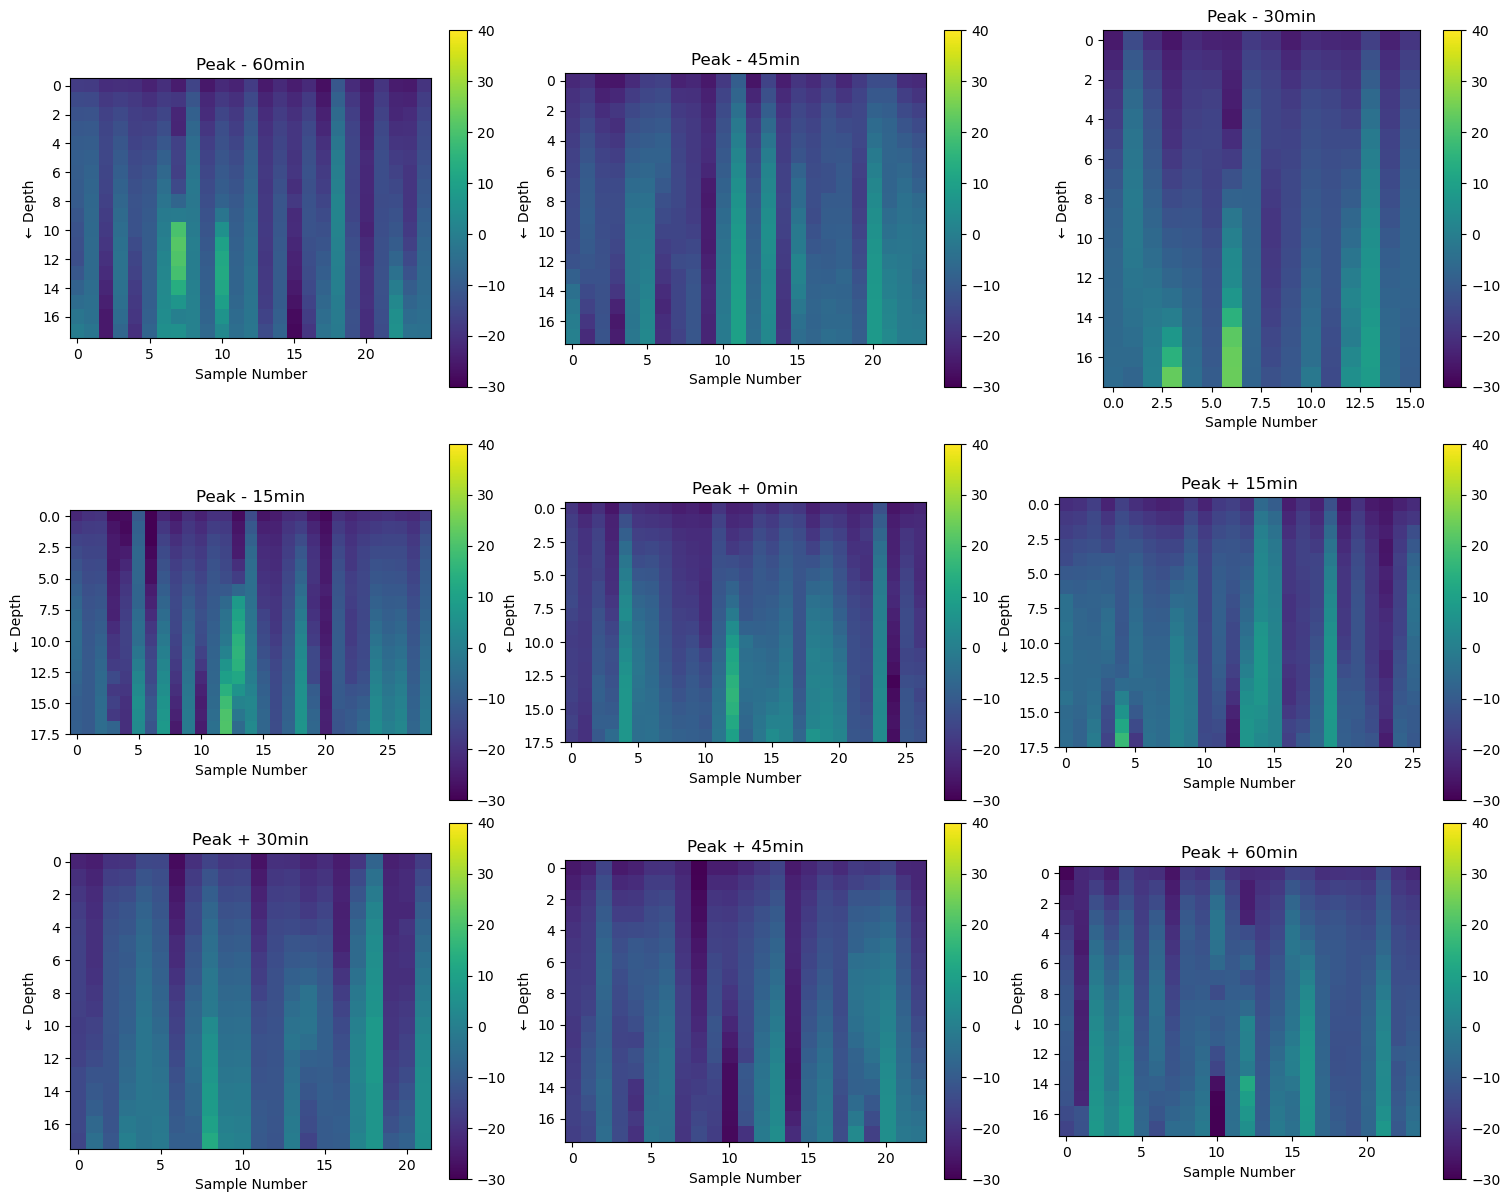

In [160]:
import numpy as np
import matplotlib.pyplot as plt

# Pre-defined index range
idx_range = range(-4, 5)   # example: Z_meas[0] ... Z_meas[5]

n = len(idx_range)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows), constrained_layout=True)
axes = np.ravel(axes)

for ax, idx in zip(axes, idx_range):
    im = ax.imshow(Z_meas[idx].T, vmin=-30, vmax=40)
    if idx >= 0: label = f"Peak + {idx*15}min"
    else: label = f"Peak - {abs(idx*15)}min"
    ax.set_title(label)
    ax.set_ylabel("← Depth")
    ax.set_xlabel("Sample Number")
    fig.colorbar(im, ax=ax)

# Hide unused subplots
for ax in axes[n:]:
    ax.axis("off")

plt.show()

In [161]:
describe(bulk_data_filtered["Glaciation time [h]"])

{'count': 1600,
 'mean': np.float64(6.18546875),
 'std': np.float64(6.668642789599203),
 'min': np.float64(0.25),
 '5%': np.float64(0.5),
 '25%': np.float64(1.75),
 '50%': np.float64(4.0),
 '75%': np.float64(8.0),
 '95%': np.float64(19.26249999999999),
 'max': np.float64(58.75)}

In [162]:
describe(bulk_data_filtered["track_length"]/pd.Timedelta(minutes=60))

{'count': 1600,
 'mean': np.float64(18.5859375),
 'std': np.float64(12.995815037776344),
 'min': np.float64(1.0),
 '5%': np.float64(3.0),
 '25%': np.float64(8.75),
 '50%': np.float64(15.5),
 '75%': np.float64(25.25),
 '95%': np.float64(43.51249999999999),
 'max': np.float64(82.5)}

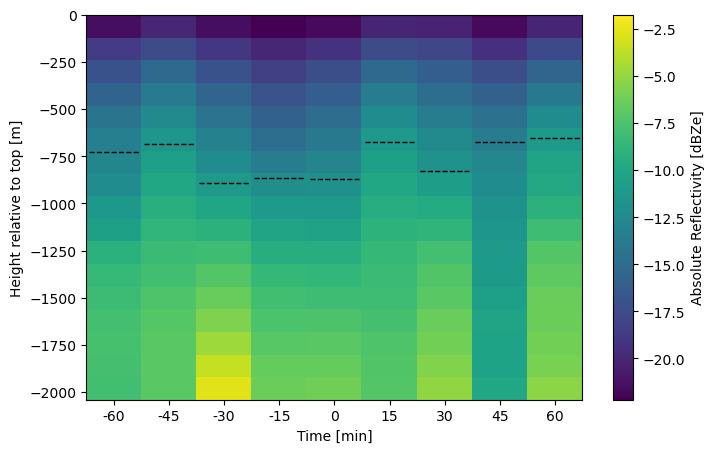

In [163]:

import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
# or: 
y_levels = test_row["bulk_level_offset_top_m"]
plot_map = np.zeros((len(y_levels), len(inds)))
ext_lev = np.zeros((len(inds)))

for col, ind in enumerate(inds):
    dbZ = Z_meas[ind]
    dbZ[~np.isfinite(dbZ)]=np.nan
    
    plot_map[:, col] = np.nanmean(dbZ,axis=0)
    ext_lev[col] = np.nanmean(ext_meas[ind])

level_means = np.tile(plot_map.mean(axis=1)[:,np.newaxis],ind_range[1]-ind_range[0])


plt.figure(figsize=(8, 5))

plt.imshow(
    plot_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        test_row["bulk_level_offset_bottom_m"][-1],
        0,
    ],
)

# plt.hlines(-(np.argmax(plot_map-level_means,axis=0)+0.5)*120,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1)
plt.hlines(-ext_lev,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="Absolute Reflectivity [dBZe]")
plt.show() 

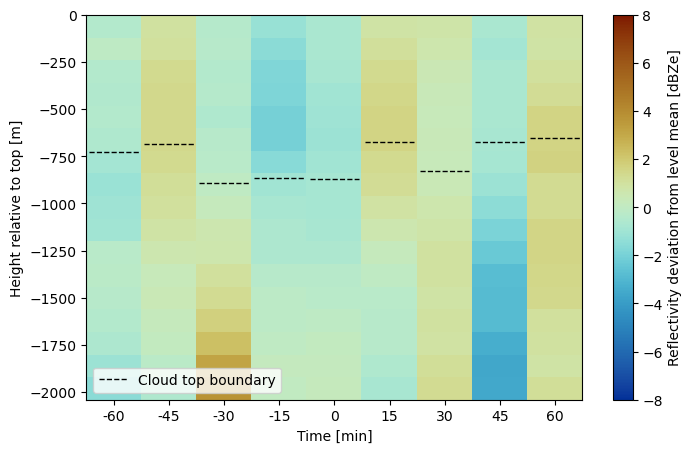

In [164]:

import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
# or: 
y_levels = test_row["bulk_level_offset_top_m"]
plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    dbZ = Z_meas[ind]
    dbZ[~np.isfinite(dbZ)]=np.nan
    ext_lev[col] = np.nanmean(ext_meas[ind])
    plot_map[:, col] = np.nanmean(dbZ,axis=0)

level_means = np.tile(plot_map.mean(axis=1)[:,np.newaxis],ind_range[1]-ind_range[0])


plt.figure(figsize=(8, 5))

plt.imshow(
    plot_map-level_means,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        test_row["bulk_level_offset_bottom_m"][-1],
        0,
    ],
    cmap=cm.roma_r,
    vmax=8,
    vmin=-8
)
plt.hlines(-ext_lev,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1, label="Cloud top boundary")

# plt.hlines(-(np.argmax(plot_map-level_means,axis=0)+0.5)*120,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="Reflectivity deviation from level mean [dBZe]")
plt.legend(loc="lower left")
plt.show() 

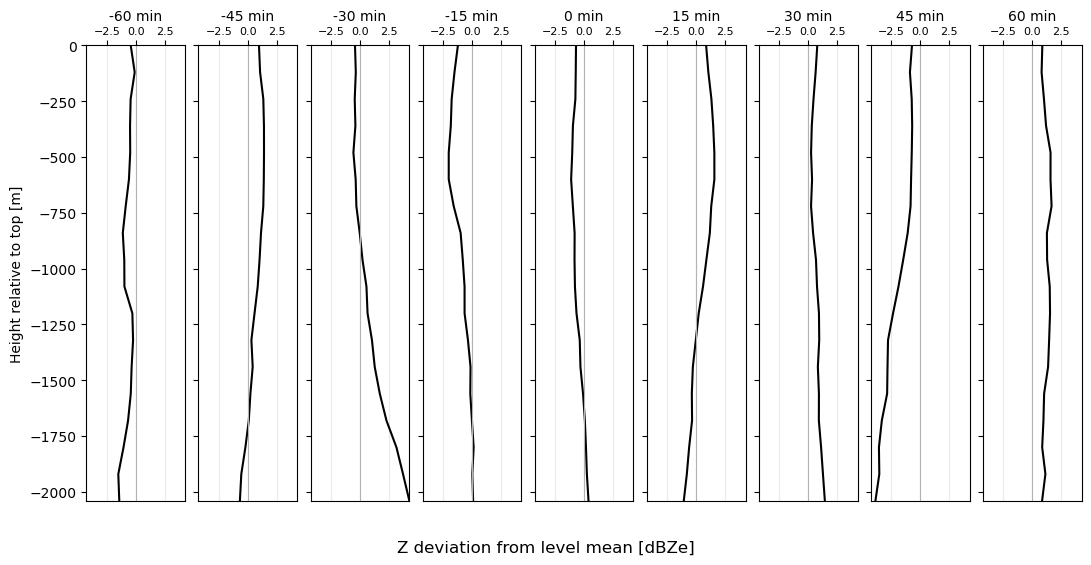

In [165]:
import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]
inds = np.arange(ind_range[0], ind_range[1])

y_levels = test_row["bulk_level_offset_top_m"]

plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    dbZ = Z_meas[ind]
    dbZ[~np.isfinite(dbZ)] = np.nan
    plot_map[:, col] = np.nanmean(dbZ, axis=0)

level_means = np.tile(
    plot_map.mean(axis=1)[:, np.newaxis],
    ind_range[1] - ind_range[0]
)

dev_map = plot_map - level_means


# Constant horizontal range for all vertical profiles
xmax = np.nanmax(np.abs(dev_map))
xlim = (-xmax, xmax)

fig, axes = plt.subplots(
    1,
    len(inds),
    figsize=(1.2 * len(inds), 5),
    sharey=True,
    constrained_layout=True
)

if len(inds) == 1:
    axes = [axes]

for ax, ind, profile in zip(axes, inds, dev_map.T):
    ax.plot(profile, y_levels, color="black", linewidth=1.5)

    max_i = np.nanargmax(profile)
    # ax.axhline(y_levels[max_i], linestyle="dashed", color="black", linewidth=1)

    ax.axvline(0, color="0.7", linewidth=0.8)

    # Same horizontal axis range everywhere
    ax.set_xlim(xlim)

    # Horizontal axes on top
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()
    ax.set_xlabel(f"{ind * 15} min")

    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", alpha=0.25)

axes[0].set_ylabel("Height relative to top [m]")

plt.ylim(y_levels[-1], y_levels[0])
fig.supxlabel("Z deviation from level mean [dBZe]", y=-0.1)

plt.show()

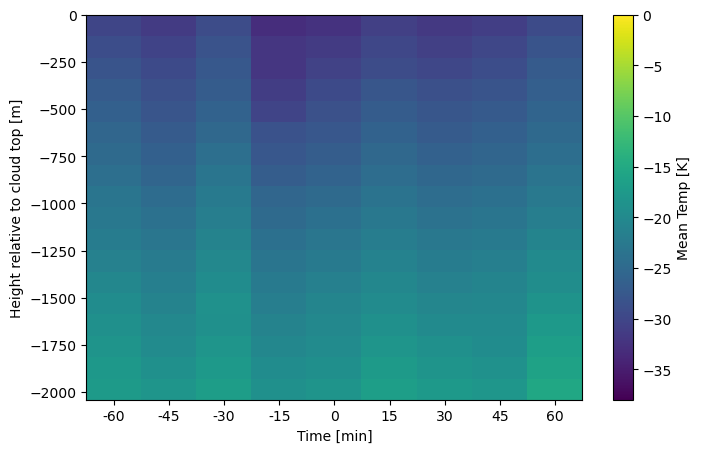

In [166]:
import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
y_levels = test_row["bulk_level_offset_top_m"]

temp_plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    
    temp_plot_map[:, col] = np.nanmean(t_meas[ind],axis=0)

level_means = np.tile(temp_plot_map.mean(axis=1)[:,np.newaxis],ind_range[1]-ind_range[0])


plt.figure(figsize=(8, 5))

plt.imshow(
    temp_plot_map-273.15,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=-38,
    vmax=0
)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to cloud top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="Mean Temp [K]")

plt.show()

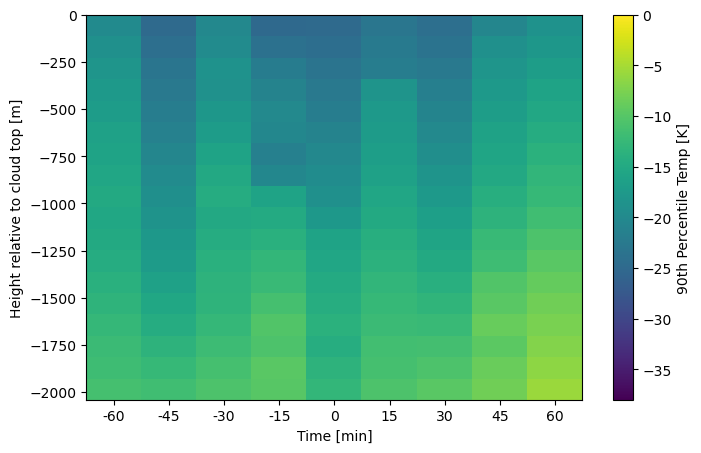

In [167]:
import numpy as np
import matplotlib.pyplot as plt

ind_range = [-4, 5]

inds = np.arange(ind_range[0], ind_range[1])   # -5, -4, ..., 4

# y_levels = test_row["bulk_level_offset_bottom_m"]
y_levels = test_row["bulk_level_offset_top_m"]

temp_plot_map = np.zeros((len(y_levels), len(inds)))

for col, ind in enumerate(inds):
    
    temp_plot_map[:, col] = np.nanpercentile(t_meas[ind],90,axis=0)


plt.figure(figsize=(8, 5))

plt.imshow(
    temp_plot_map-273.15,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=-38,
    vmax=0
)

plt.xticks(inds, inds*15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to cloud top [m]")

plt.ylim(y_levels[-1], y_levels[0])  # bottom negative, top 0
plt.colorbar(label="90th Percentile Temp [K]")

plt.show()

In [168]:
describe(Z_meas[-2])

{'count': 288,
 'mean': np.float32(-10.168902),
 'std': np.float32(8.479781),
 'min': np.float32(-25.800888),
 '5%': np.float32(-22.052187),
 '25%': np.float32(-15.961547),
 '50%': np.float32(-11.181688),
 '75%': np.float32(-6.2169666),
 '95%': np.float32(5.3976398),
 'max': np.float32(23.997387)}

## Mean Version

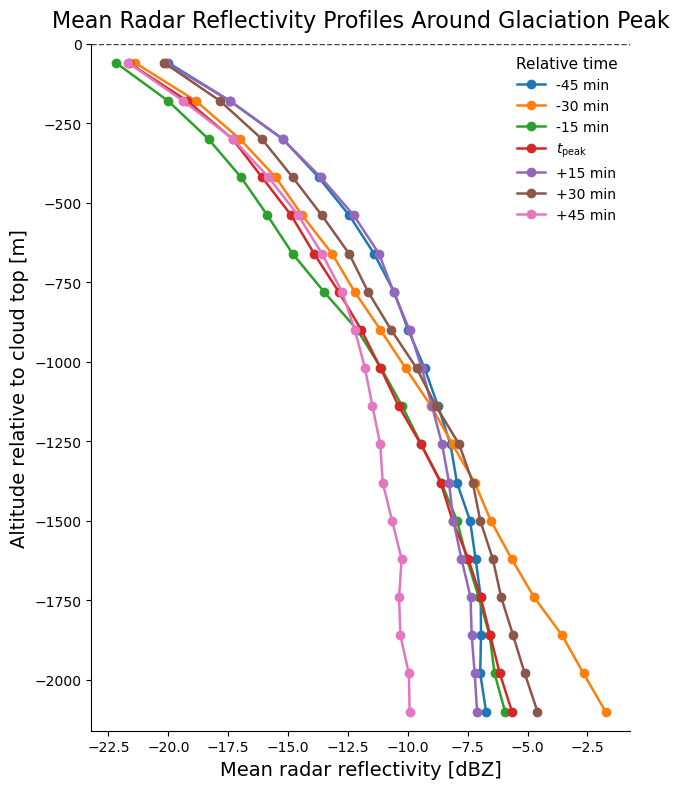

In [169]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Times to plot
# ------------------------------------------------------------
target_times = [-45, -30, -15, 0, 15, 30, 45]

df_plot = (
    stats_by_rel_time[
        stats_by_rel_time["rel_time_min"].isin(target_times)
    ]
    .sort_values("rel_time_min")
    .copy()
)

missing = sorted(set(target_times) - set(df_plot["rel_time_min"]))
if missing:
    print(f"Warning: missing requested relative times: {missing}")

# ------------------------------------------------------------
# Plot mean dBZ profile at each relative time
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.5, 8))

for _, row in df_plot.iterrows():
    rel_time = row["rel_time_min"]

    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z_dbz = np.asarray(row["mean_Z_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z_dbz))
    top = top[:n]
    bottom = bottom[:n]
    z_dbz = z_dbz[:n]

    # Use bin midpoint as vertical coordinate
    height_mid = 0.5 * (top + bottom)

    mask = (
        np.isfinite(height_mid)
        & np.isfinite(z_dbz)
    )

    height_mid = height_mid[mask]
    z_dbz = z_dbz[mask]

    # Sort vertically
    order = np.argsort(height_mid)
    height_mid = height_mid[order]
    z_dbz = z_dbz[order]

    if rel_time == 0:
        label = r"$t_{\mathrm{peak}}$"
    elif rel_time < 0:
        label = f"{rel_time} min"
    else:
        label = f"+{rel_time} min"

    ax.plot(
        z_dbz,
        height_mid,
        marker="o",
        linewidth=1.8,
        label=label,
    )

# ------------------------------------------------------------
# Styling
# ------------------------------------------------------------
ax.axhline(
    0,
    linestyle="--",
    linewidth=1.0,
    color="0.25"
)

ax.set_xlabel("Mean radar reflectivity [dBZ]", fontsize=14)
ax.set_ylabel("Altitude relative to cloud top [m]", fontsize=14)

ax.set_title(
    "Mean Radar Reflectivity Profiles Around Glaciation Peak",
    fontsize=16,
    pad=12,
)

ax.set_ylim(
    np.nanmin([
        np.nanmin(np.asarray(v, dtype=float))
        for v in df_plot["bulk_offset_bottom_m"]
    ]),
    0
)

ax.legend(
    title="Relative time",
    frameon=False,
    fontsize=10,
    title_fontsize=11,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "mean_radar_reflectivity_profiles_by_relative_time.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)

plt.show()

In [170]:
bulk_data_df_split.apply(lambda row: (row["surface_type"]=="maritime").all()>=1, axis=1).value_counts()

True     3231
False    2800
Name: count, dtype: int64

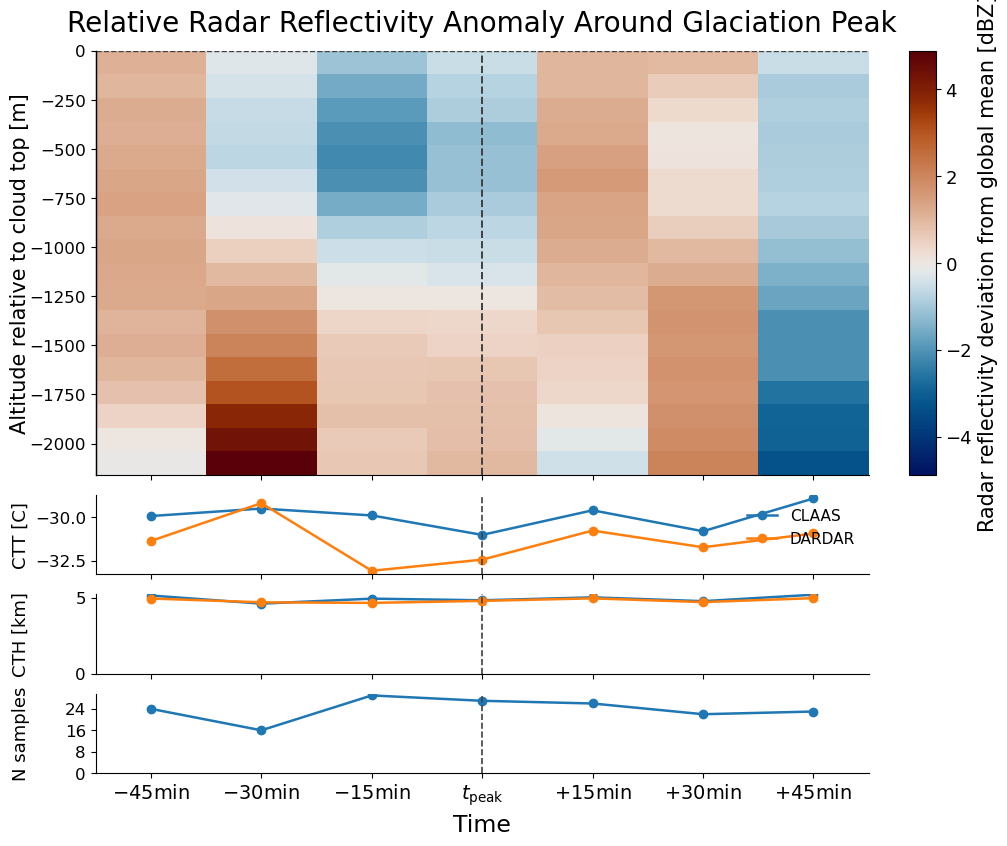

In [171]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from cmcrameri import cm

# ------------------------------------------------------------
# Times to plot
# ------------------------------------------------------------
target_times = [-45, -30, -15, 0, 15, 30, 45]

df_plot = (
    stats_by_rel_time[
        stats_by_rel_time["rel_time_min"].isin(target_times)
    ]
    .sort_values("rel_time_min")
    .copy()
)

missing = sorted(set(target_times) - set(df_plot["rel_time_min"]))
if missing:
    print(f"Warning: missing requested relative times: {missing}")

# ------------------------------------------------------------
# Compute all-time mean radar reflectivity profile by vertical level
# ------------------------------------------------------------
level_values = {}

for _, row in stats_by_rel_time.iterrows():
    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_Z_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
    )

    for t, b, val in zip(top[mask], bottom[mask], z[mask]):
        key = (float(t), float(b))
        level_values.setdefault(key, []).append(val)

all_time_mean_by_level = {
    key: np.nanmean(vals)
    for key, vals in level_values.items()
}

# ------------------------------------------------------------
# Build radar reflectivity anomaly records
# ------------------------------------------------------------
records = []

for _, row in df_plot.iterrows():
    rel_time = row["rel_time_min"]

    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_Z_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
    )

    top = top[mask]
    bottom = bottom[mask]
    z = z[mask]

    for t, b, val in zip(top, bottom, z):
        key = (float(t), float(b))
        mean_val = all_time_mean_by_level.get(key, np.nan)

        if np.isfinite(mean_val):
            anomaly = val - mean_val  # dBZ anomaly
        else:
            anomaly = np.nan

        records.append(
            {
                "rel_time_min": rel_time,
                "top": t,
                "bottom": b,
                "anomaly": anomaly,
            }
        )

anomaly_vals = np.asarray([
    r["anomaly"] for r in records
    if np.isfinite(r["anomaly"])
])

if len(anomaly_vals) == 0:
    raise ValueError("No finite radar reflectivity anomaly values found.")

absmax = np.nanmax(np.abs(anomaly_vals))

norm = TwoSlopeNorm(
    vmin=-absmax,
    vcenter=0,
    vmax=absmax
)

cmap = cm.vik

# ------------------------------------------------------------
# Figure layout: heatmap + 3 shallow line plots + colorbar column
# ------------------------------------------------------------
fig = plt.figure(figsize=(10.5, 8.6))
fig.patch.set_alpha(0)

gs = GridSpec(
    nrows=4,
    ncols=2,
    width_ratios=[1, 0.035],
    height_ratios=[5.6, 1.05, 1.05, 1.05],
    hspace=0.12,
    wspace=0.10
)

ax = fig.add_subplot(gs[0, 0])
ax_ctt = fig.add_subplot(gs[1, 0], sharex=ax)
ax_cth = fig.add_subplot(gs[2, 0], sharex=ax)
ax_hits = fig.add_subplot(gs[3, 0], sharex=ax)

# Dedicated colorbar axis, only next to the heatmap
cax = fig.add_subplot(gs[0, 1])

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.set_facecolor("none")

cax.set_facecolor("none")

# ------------------------------------------------------------
# Main radar reflectivity anomaly heatmap
# ------------------------------------------------------------
x_width = 15.0

for rel_time in df_plot["rel_time_min"].values:
    row_records = [
        r for r in records
        if r["rel_time_min"] == rel_time
        and np.isfinite(r["anomaly"])
    ]

    if len(row_records) == 0:
        continue

    x_left = rel_time - x_width / 2

    row_records = sorted(
        row_records,
        key=lambda r: min(r["top"], r["bottom"])
    )

    for r in row_records:
        y_low = min(r["top"], r["bottom"])
        height = abs(r["bottom"] - r["top"])

        rect = Rectangle(
            (x_left, y_low),
            x_width,
            height,
            facecolor=cmap(norm(r["anomaly"])),
            edgecolor="none",
            hatch=None,
            zorder=1
        )
        ax.add_patch(rect)

    # Add hatched gaps between vertical bins, if any
    intervals = []

    for r in row_records:
        y0 = min(r["top"], r["bottom"])
        y1 = max(r["top"], r["bottom"])
        intervals.append((y0, y1))

    intervals = sorted(intervals, key=lambda p: p[0])

    for (prev_low, prev_high), (next_low, next_high) in zip(
        intervals[:-1],
        intervals[1:]
    ):
        if next_low > prev_high and not np.isclose(next_low, prev_high):
            gap_low = prev_high
            gap_height = next_low - prev_high

            gap_rect = Rectangle(
                (x_left, gap_low),
                x_width,
                gap_height,
                facecolor="white",
                edgecolor="0.4",
                hatch="///",
                linewidth=0.0,
                zorder=2
            )
            ax.add_patch(gap_rect)

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(
    "Radar reflectivity deviation from global mean [dBZ]",
    fontsize=15
)
cbar.ax.tick_params(labelsize=13)

# ------------------------------------------------------------
# Main axis styling
# ------------------------------------------------------------
ax.set_title(
    "Relative Radar Reflectivity Anomaly Around Glaciation Peak",
    fontsize=20,
    pad=14,
)

ax.set_ylabel("Altitude relative to cloud top [m]", fontsize=17)

all_tops = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_top_m"]
])

all_bottoms = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_bottom_m"]
])

ax.set_ylim(
    np.nanmin([all_tops.min(), all_bottoms.min()]),
    0
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.4,
    color="0.25",
    zorder=4
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1.0,
    color="0.25",
    zorder=4
)

# Hide x tick labels on upper panel
plt.setp(ax.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Cloud top temperature line plot
# ------------------------------------------------------------
times = df_plot["rel_time_min"].to_numpy(dtype=float)

ax_ctt.plot(
    times,
    df_plot["sev_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="CLAAS"
)

ax_ctt.plot(
    times,
    df_plot["dd_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="DARDAR"
)

ax_ctt.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_ctt.set_ylabel("CTT [C]", fontsize=13)
ax_ctt.tick_params(axis="y", labelsize=12)
ax_ctt.legend(
    frameon=False,
    fontsize=11,
    loc="upper right"
)

plt.setp(ax_ctt.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Mean cloud top height line plot
# ------------------------------------------------------------
ax_cth.plot(
    times,
    df_plot["dd_cth"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8,
    label="DARDAR"
)

ax_cth.plot(
    times,
    df_plot["sev_cth"].to_numpy(dtype=float) / 1000,
    marker="o",
    linewidth=1.8,
    label="CLAAS"
)

ax_cth.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_cth.set_ylabel("CTH [km]", fontsize=13)
ax_cth.tick_params(axis="y", labelsize=12)
ax_cth.set_ylim(0)

plt.setp(ax_cth.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# n_hits line plot
# ------------------------------------------------------------
ax_hits.plot(
    times,
    df_plot["n_hits"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8
)

ax_hits.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_hits.set_ylabel("N samples", fontsize=13)
ax_hits.tick_params(axis="y", labelsize=12)
ax_hits.yaxis.set_major_locator(
    MaxNLocator(nbins=4, integer=True)
)
ax_hits.set_ylim(0)

# ------------------------------------------------------------
# Consistent y-axis label styling and alignment
# ------------------------------------------------------------
ylabel_fontsize = 13
ylabel_pad = 42

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.yaxis.label.set_size(ylabel_fontsize)
    a.yaxis.labelpad = ylabel_pad
    a.yaxis.set_label_coords(-0.085, 0.5)
    a.tick_params(axis="y", labelsize=12)

# Make main heatmap label slightly larger
ax.yaxis.label.set_size(15)

# ------------------------------------------------------------
# Shared x-axis formatting
# ------------------------------------------------------------
ax_hits.set_xlim(
    min(target_times) - x_width / 2,
    max(target_times) + x_width / 2,
)

ax_hits.set_xlabel("Time", fontsize=17)

ax_hits.set_xticks(target_times)

ax_hits.set_xticklabels(
    [
        r"$- 45\mathrm{min}$",
        r"$- 30\mathrm{min}$",
        r"$- 15\mathrm{min}$",
        r"$t_{\mathrm{peak}}$",
        r"$+ 15\mathrm{min}$",
        r"$+ 30\mathrm{min}$",
        r"$+ 45\mathrm{min}$",
    ],
    fontsize=14,
)

# ------------------------------------------------------------
# Clean style
# ------------------------------------------------------------
for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    a.spines["left"].set_zorder(10)
    a.spines["bottom"].set_zorder(10)

# Redraw left axis line on heatmap, if patches cover it
ax.axvline(
    ax.get_xlim()[0],
    color="black",
    linewidth=1.0,
    zorder=10,
    clip_on=False
)

fig.subplots_adjust(
    left=0.10,
    right=0.90,
    top=0.94,
    bottom=0.10
)

plt.savefig(
    "relative_radar_reflectivity_anomaly_heatmap_with_ctt_cth_nhits_panels.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)

plt.show()

In [172]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from cmcrameri import cm

# ------------------------------------------------------------
# Times to plot
# ------------------------------------------------------------
target_times = [ -60, -45, -30, -15, 0, 15, 30, 45, 60]

df_plot = (
    stats_by_rel_time[
        stats_by_rel_time["rel_time_min"].isin(target_times)
    ]
    .sort_values("rel_time_min")
    .copy()
)

missing = sorted(set(target_times) - set(df_plot["rel_time_min"]))
if missing:
    print(f"Warning: missing requested relative times: {missing}")

# ------------------------------------------------------------
# Compute all-time mean profile by actual vertical level
# ------------------------------------------------------------
level_values = {}

for _, row in stats_by_rel_time.iterrows():
    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_iwc_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
        & (z > 0)
    )

    for t, b, val in zip(top[mask], bottom[mask], z[mask]):
        key = (float(t), float(b))
        level_values.setdefault(key, []).append(val)

all_time_mean_by_level = {
    key: np.nanmean(vals)
    for key, vals in level_values.items()
}
# mean_iwc_all = np.nanmean(
#     np.stack(stats_by_rel_time["mean_iwc_profile"].to_numpy())
# )
# all_time_mean_by_level = {
#     key: mean_iwc_all
#     for key, vals in level_values.items()
# }


# ------------------------------------------------------------
# Build anomaly records
# ------------------------------------------------------------
records = []

for _, row in df_plot.iterrows():
    rel_time = row["rel_time_min"]

    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_iwc_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
        & (z > 0)
    )

    top = top[mask]
    bottom = bottom[mask]
    z = z[mask]

    for t, b, val in zip(top, bottom, z):
        key = (float(t), float(b))
        mean_val = all_time_mean_by_level.get(key, np.nan)

        if np.isfinite(mean_val) and mean_val > 0:
            anomaly = 100 * (val - mean_val) / mean_val
        else:
            anomaly = np.nan

        records.append(
            {
                "rel_time_min": rel_time,
                "top": t,
                "bottom": b,
                "anomaly": anomaly,
            }
        )

anomaly_vals = np.asarray([
    r["anomaly"] for r in records
    if np.isfinite(r["anomaly"])
])

absmax = np.nanmax(np.abs(anomaly_vals))

norm = TwoSlopeNorm(
    vmin=-absmax,
    vcenter=0,
    vmax=absmax
)

cmap = cm.vik

# ------------------------------------------------------------
# Figure layout: heatmap + 3 shallow line plots + colorbar column
# ------------------------------------------------------------
fig = plt.figure(figsize=(10.5, 8.6))
fig.patch.set_alpha(0)

gs = GridSpec(
    nrows=4,
    ncols=2,
    width_ratios=[1, 0.035],
    height_ratios=[5.6, 1.05, 1.05, 1.05],
    hspace=0.12,
    wspace=0.10
)

ax = fig.add_subplot(gs[0, 0])
ax_ctt = fig.add_subplot(gs[1, 0], sharex=ax)
ax_cth = fig.add_subplot(gs[2, 0], sharex=ax)
ax_hits = fig.add_subplot(gs[3, 0], sharex=ax)

# dedicated colorbar axis, only next to the heatmap
cax = fig.add_subplot(gs[0, 1])

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.set_facecolor("none")

cax.set_facecolor("none")

# ------------------------------------------------------------
# Main heatmap
# ------------------------------------------------------------
x_width = 15.0

for rel_time in df_plot["rel_time_min"].values:
    row_records = [
        r for r in records
        if r["rel_time_min"] == rel_time
        and np.isfinite(r["anomaly"])
    ]

    if len(row_records) == 0:
        continue

    x_left = rel_time - x_width / 2

    row_records = sorted(row_records, key=lambda r: min(r["top"], r["bottom"]))

    for r in row_records:
        y_low = min(r["top"], r["bottom"])
        height = abs(r["bottom"] - r["top"])

        rect = Rectangle(
            (x_left, y_low),
            x_width,
            height,
            facecolor=cmap(norm(r["anomaly"])),
            edgecolor="none",
            hatch=None,
            zorder=1
        )
        ax.add_patch(rect)

    intervals = []

    for r in row_records:
        y0 = min(r["top"], r["bottom"])
        y1 = max(r["top"], r["bottom"])
        intervals.append((y0, y1))

    intervals = sorted(intervals, key=lambda p: p[0])

    for (prev_low, prev_high), (next_low, next_high) in zip(intervals[:-1], intervals[1:]):
        if next_low > prev_high and not np.isclose(next_low, prev_high):
            gap_low = prev_high
            gap_height = next_low - prev_high

            gap_rect = Rectangle(
                (x_left, gap_low),
                x_width,
                gap_height,
                facecolor="white",
                edgecolor="0.4",
                hatch="///",
                linewidth=0.0,
                zorder=2
            )
            ax.add_patch(gap_rect)

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("IWC deviation from global mean [%]", fontsize=15)
cbar.ax.tick_params(labelsize=13)

# ------------------------------------------------------------
# Main axis styling
# ------------------------------------------------------------
ax.set_title(
    "Relative IWC Anomaly Around Glaciation Peak",
    fontsize=20,
    pad=14,
)

ax.set_ylabel("Altitude relative to cloud top [m]", fontsize=17)

all_tops = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_top_m"]
])

all_bottoms = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_bottom_m"]
])

ax.set_ylim(
    np.nanmin([all_tops.min(), all_bottoms.min()]),
    0
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.4,
    color="0.25",
    zorder=4
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1.0,
    color="0.25",
    zorder=4
)

# Hide x tick labels on upper panels
plt.setp(ax.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Cloud top temperature line plot
# ------------------------------------------------------------
times = df_plot["rel_time_min"].to_numpy(dtype=float)

ax_ctt.plot(
    times,
    df_plot["sev_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="CLAAS"
)

ax_ctt.plot(
    times,
    df_plot["dd_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="DARDAR"
)

ax_ctt.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_ctt.set_ylabel("CTT [C]", fontsize=13)
ax_ctt.tick_params(axis="y", labelsize=12)
ax_ctt.legend(
    frameon=False,
    fontsize=11,
    loc="upper right"
)

plt.setp(ax_ctt.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Mean cloud top height line plot
# ------------------------------------------------------------
ax_cth.plot(
    times,
    df_plot["dd_cth"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8
)
ax_cth.plot(
    times,
    df_plot["sev_cth"].to_numpy(dtype=float)/1000,
    marker="o",
    linewidth=1.8
)

ax_cth.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_cth.set_ylabel("CTH [km]", fontsize=13)
ax_cth.tick_params(axis="y", labelsize=12)
ax_cth.set_ylim(0)
plt.setp(ax_cth.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# n_hits line plot
# ------------------------------------------------------------
ax_hits.plot(
    times,
    df_plot["n_hits"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8
)

ax_hits.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_hits.set_ylabel("N samples", fontsize=13)
ax_hits.tick_params(axis="y", labelsize=12)
ax_hits.yaxis.set_major_locator(
    MaxNLocator(nbins=4, integer=True)
)
ax_hits.set_ylim(0)

# ------------------------------------------------------------
# Consistent y-axis label styling and alignment
# ------------------------------------------------------------
ylabel_fontsize = 13
ylabel_pad = 42

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.yaxis.label.set_size(ylabel_fontsize)
    a.yaxis.labelpad = ylabel_pad
    a.yaxis.set_label_coords(-0.085, 0.5)
    a.tick_params(axis="y", labelsize=12)

# Make main heatmap label slightly larger only if desired
ax.yaxis.label.set_size(15)
# ------------------------------------------------------------
# Shared x-axis formatting
# ------------------------------------------------------------
ax_hits.set_xlim(
    min(target_times) - x_width / 2,
    max(target_times) + x_width / 2,
)

ax_hits.set_xlabel("Time", fontsize=17)

ax_hits.set_xticks(target_times)


ax_hits.set_xticklabels(
    [
        r"$- 60\mathrm{min}$",
        r"$- 45\mathrm{min}$",
        r"$- 30\mathrm{min}$",
        r"$- 15\mathrm{min}$",
        r"$t_{\mathrm{peak}}$",
        r"$+ 15\mathrm{min}$",
        r"$+ 30\mathrm{min}$",
        r"$+ 45\mathrm{min}$",
        r"$+ 60\mathrm{min}$",
    ],
    fontsize=14,
)

# ------------------------------------------------------------
# Clean style
# ------------------------------------------------------------
for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    a.spines["left"].set_zorder(10)
    a.spines["bottom"].set_zorder(10)

# redraw left axis line on heatmap, if patches cover it
ax.axvline(
    ax.get_xlim()[0],
    color="black",
    linewidth=1.0,
    zorder=10,
    clip_on=False
)

fig.subplots_adjust(
    left=0.10,
    right=0.90,
    top=0.94,
    bottom=0.10
)

plt.savefig(
    "relative_iwc_anomaly_heatmap_with_ctt_cth_nhits_panels.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)

plt.show()

ValueError: zero-size array to reduction operation fmax which has no identity

# Significance statistics

In [196]:
from scipy.stats import t
import numpy as np
ind_range = [-4,5]
inds = np.arange(ind_range[0], ind_range[1])
y_levels = test_row["bulk_level_offset_top_m"]
n_levels = len(y_levels)
n_times = len(inds)

mean_map = np.full((n_levels, n_times), np.nan)
std_map  = np.full((n_levels, n_times), np.nan)
n_map    = np.full((n_levels, n_times), np.nan)

dbZ_by_ind = {}

for col, ind in enumerate(inds):
    dbZ = Z_meas[ind]
    dbZ[~np.isfinite(dbZ)] = np.nan
    
    dbZ_by_ind[ind] = dbZ

    mean_map[:, col] = np.nanmean(dbZ, axis=0)
    std_map[:, col]  = np.nanstd(dbZ, axis=0, ddof=1)
    n_map[:, col]    = np.sum(np.isfinite(dbZ), axis=0)

sem_map = std_map / np.sqrt(n_map)

In [197]:
from scipy.stats import t
import numpy as np

def remove_outliers_iqr(x, k=1.5):
    x = x[np.isfinite(x)]

    if len(x) < 4:
        return x

    q1, q3 = np.nanpercentile(x, [25, 75])
    iqr = q3 - q1

    if iqr == 0 or not np.isfinite(iqr):
        return x

    lower = q1 - k * iqr
    upper = q3 + k * iqr

    return x[(x >= lower) & (x <= upper)]

def remove_outliers_trim(x, skip=2):
    x = x[np.isfinite(x)]
    x.sort()
    return x[skip:-skip]
p_welch_map = np.full_like(mean_map, np.nan)
dev_vs_others_map = np.full_like(mean_map, np.nan)
effect_size_map = np.full_like(mean_map, np.nan)

n_x_map = np.full_like(mean_map, np.nan)
n_y_raw_map = np.full_like(mean_map, np.nan)
n_y_clean_map = np.full_like(mean_map, np.nan)

for j, ind in enumerate(inds):
    xmat = dbZ_by_ind[ind]

    other_inds = [k for k in inds if k != ind]
    ymat = np.vstack([dbZ_by_ind[k] for k in other_inds])

    for i in range(n_levels):
        x = xmat[:, i]
        y = ymat[:, i]

        x = x[np.isfinite(x)]
        y = y[np.isfinite(y)]

        n_y_raw = len(y)

        # Remove outliers only from y, as requested
        # y = remove_outliers_iqr(y, k=1.5)
        # x = remove_outliers_iqr(x, k=1.5)
        y = remove_outliers_trim(y, skip=2)
        x = remove_outliers_trim(x, skip=2)

        if len(x) < 2 or len(y) < 2:
            continue

        mx, my = np.mean(x), np.mean(y)
        vx, vy = np.var(x, ddof=1), np.var(y, ddof=1)
        nx, ny = len(x), len(y)

        dev = mx - my
        se = np.sqrt(vx / nx + vy / ny)

        if se == 0 or not np.isfinite(se):
            continue

        tval = dev / se

        df_num = (vx / nx + vy / ny) ** 2
        df_den = ((vx / nx) ** 2) / (nx - 1) + ((vy / ny) ** 2) / (ny - 1)

        if df_den == 0 or not np.isfinite(df_den):
            continue

        df = df_num / df_den

        p = 2 * t.sf(np.abs(tval), df)

        pooled_sd = np.sqrt((vx + vy) / 2)

        p_welch_map[i, j] = p
        dev_vs_others_map[i, j] = dev

        if pooled_sd > 0 and np.isfinite(pooled_sd):
            effect_size_map[i, j] = dev / pooled_sd

        n_x_map[i, j] = nx
        n_y_raw_map[i, j] = n_y_raw
        n_y_clean_map[i, j] = ny

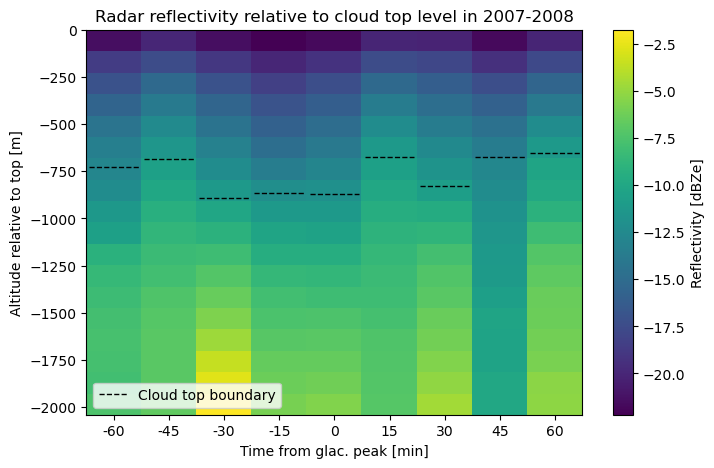

In [198]:
plt.figure(figsize=(8, 5))
sig_map = -np.log10(p_welch_map)
plt.imshow(
    mean_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    # vmin=-7,
    # vmax=7,
    # cmap=cm.roma_r
)
plt.hlines(-ext_lev,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1, label="Cloud top boundary")

plt.xticks(inds, inds * 15)
plt.xlabel("Time from glac. peak [min]")
plt.ylabel("Altitude relative to top [m]")
plt.colorbar(label="Reflectivity [dBZe]")
plt.title("Radar reflectivity relative to cloud top level in 2007-2008")
plt.legend(loc="lower left")
plt.show()

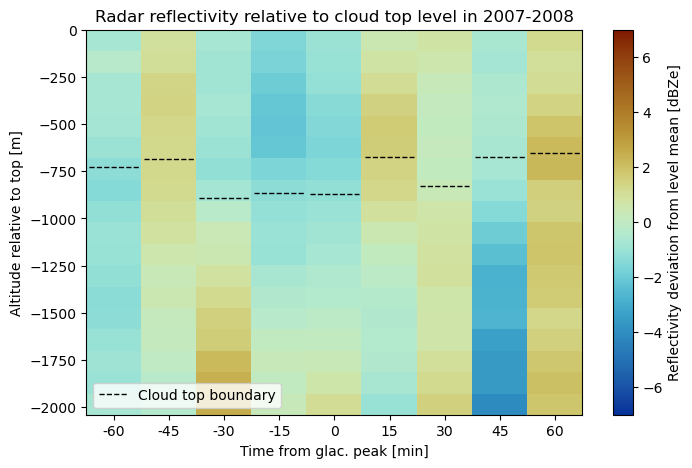

In [199]:
plt.figure(figsize=(8, 5))
plt.imshow(
    dev_vs_others_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=-7,
    vmax=7,
    cmap=cm.roma_r
)
plt.hlines(-ext_lev,inds-0.45, inds+0.45,linestyles="dashed",colors="black",linewidth=1, label="Cloud top boundary")

plt.xticks(inds, inds * 15)
plt.xlabel("Time from glac. peak [min]")
plt.ylabel("Altitude relative to top [m]")
plt.colorbar(label="Reflectivity deviation from level mean [dBZe]")
plt.title("Radar reflectivity relative to cloud top level in 2007-2008")
plt.legend(loc="lower left")
plt.show()
# plt.savefig()

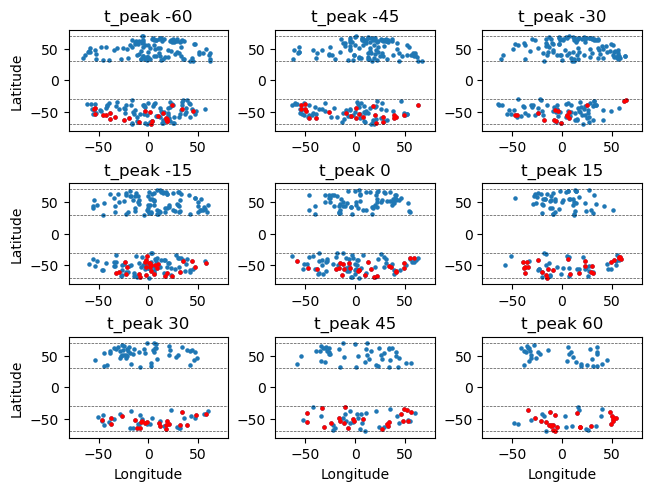

In [200]:
n = len(inds)
nrows = 3
ncols = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, constrained_layout=True)

for i, ind in enumerate(inds):
    row=i//3
    col=i%3
    # print(row,col)
    selected_clouds = bulk_data_df_split[bulk_data_df_split["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds["avg_lon"],selected_clouds["avg_lat"], s=5)
    selected_clouds_filt = bulk_data_filtered[bulk_data_filtered["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds_filt["avg_lon"],selected_clouds_filt["avg_lat"],color='red',s=5)
    axes[row,col].set_title(f"t_peak {ind*15}")
    # axes[row,col].set_xscale("log")
    # axes[row,col].set_xlim(0,1e6)
    # axes[row,col].set_ylim(0,40)
    for line_lat in [-70,-30,30,70]:
        axes[row,col].axhline(line_lat,linestyle="--",linewidth=0.5,color="black",alpha=0.7)
    if col==0:
        axes[row,col].set_ylabel("Latitude")
    if row==2:
        axes[row,col].set_xlabel("Longitude")
    axes[row,col].set_ylim(-80,80)
    axes[row,col].set_xlim(-80,80)

plt.show()

/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/opt/miniconda3/envs/gte_env/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs

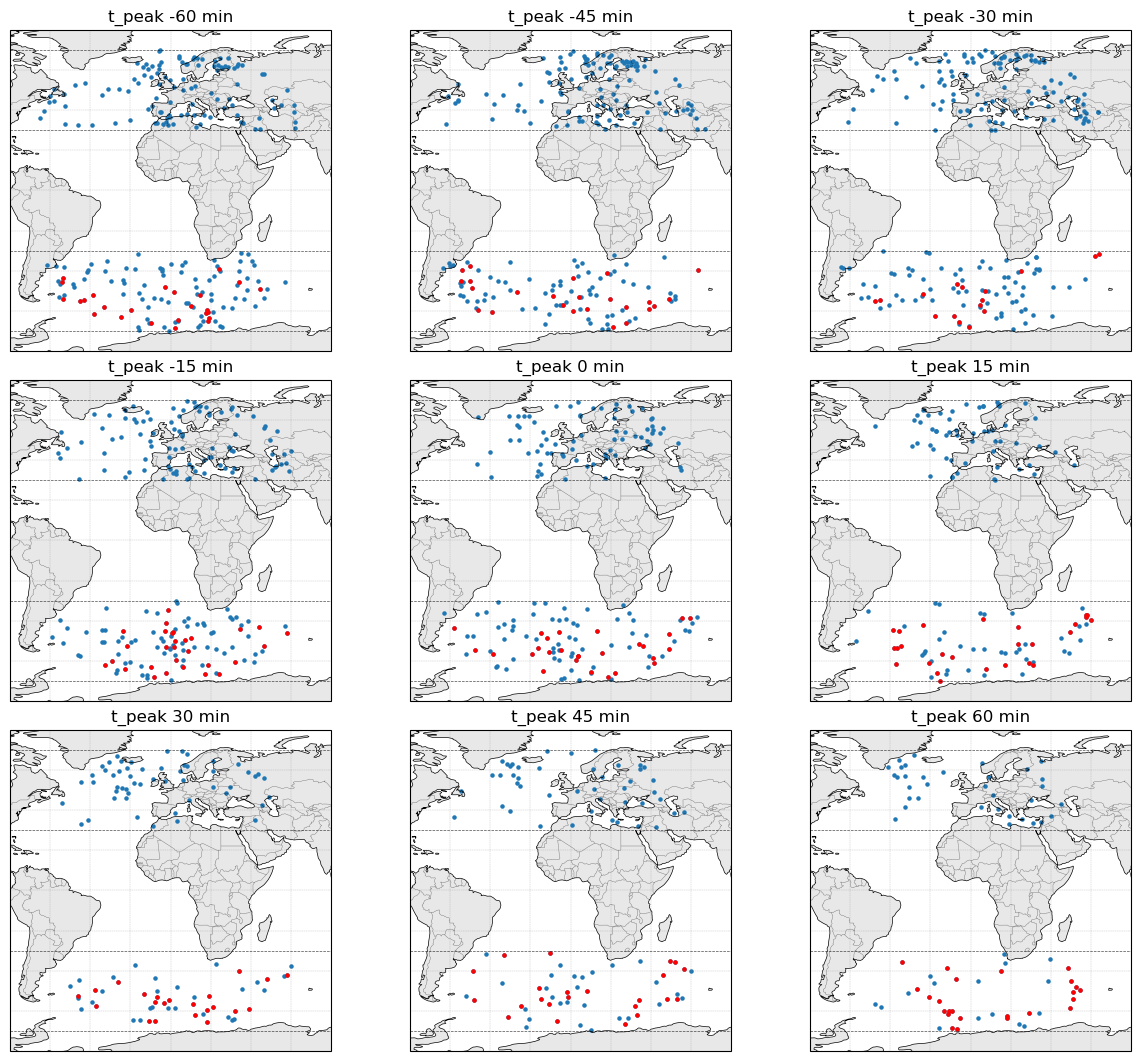

In [201]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

n = len(inds)
nrows = 3
ncols = int(np.ceil(n / nrows))

proj = ccrs.PlateCarree()

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(4 * ncols, 3.5 * nrows),
    subplot_kw={"projection": proj},
    constrained_layout=True
)

axes = np.asarray(axes).reshape(nrows, ncols)

for i, ind in enumerate(inds):
    row = i // ncols
    col = i % ncols
    ax = axes[row, col]

    selected_clouds = bulk_data_df_split[bulk_data_df_split["rel_ind"] == ind]
    selected_clouds_filt = bulk_data_filtered[bulk_data_filtered["rel_ind"] == ind]

    # Map background
    ax.set_extent([-80, 80, -80, 80], crs=proj)
    ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.5)
    ax.add_feature(cfeature.OCEAN, facecolor="white", alpha=0.8)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, alpha=0.5)

    # Optional gridlines
    gl = ax.gridlines(
        crs=proj,
        draw_labels=False,
        linewidth=0.3,
        color="gray",
        alpha=0.5,
        linestyle="--"
    )

    # Scatter points
    ax.scatter(
        selected_clouds["avg_lon"],
        selected_clouds["avg_lat"],
        s=5,
        transform=proj,
        label="All"
    )

    ax.scatter(
        selected_clouds_filt["avg_lon"],
        selected_clouds_filt["avg_lat"],
        color="red",
        s=5,
        transform=proj,
        label="Filtered"
    )

    ax.set_title(f"t_peak {ind * 15} min")

    # Latitude guide lines
    for line_lat in [-70, -30, 30, 70]:
        ax.plot(
            [-80, 80],
            [line_lat, line_lat],
            linestyle="--",
            linewidth=0.5,
            color="black",
            alpha=0.7,
            transform=proj
        )

    if col == 0:
        ax.set_ylabel("Latitude")

    if row == nrows - 1:
        ax.set_xlabel("Longitude")
    # axes[row,col].axhline(selected_clouds_filt["avg_ctt"].mean()-273.15,linestyle="--",linewidth=0.5,color="red")
    # axes[row,col].axvline(selected_clouds_filt["avg_cot"].mean(),linestyle="--",linewidth=0.5,color="red")

# Hide unused axes
for j in range(n, nrows * ncols):
    row = j // ncols
    col = j % ncols
    axes[row, col].set_visible(False)

plt.show()

/var/folders/ps/bdhslmwj4t16q5_v16j9hwmc0000gt/T/ipykernel_18167/3380338885.py:17: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  axes[row,col].set_xlim(0,1e6)


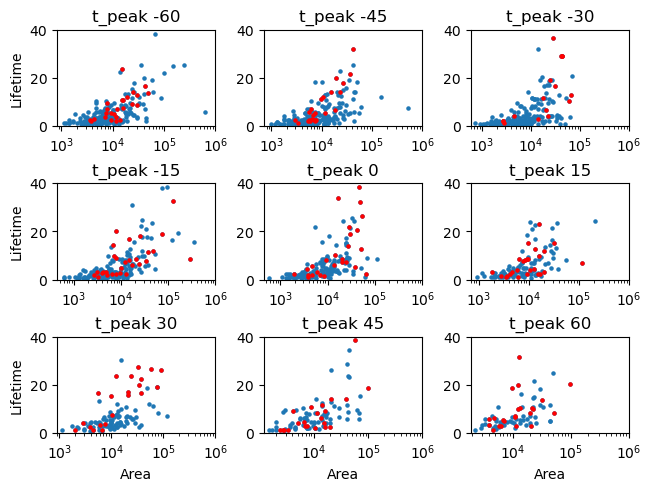

In [202]:
n = len(inds)
nrows = 3
ncols = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, constrained_layout=True)

for i, ind in enumerate(inds):
    row=i//3
    col=i%3
    # print(row,col)
    selected_clouds = bulk_data_df_split[bulk_data_df_split["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds["avg_size[km]"],selected_clouds["Lifetime [h]"], s=5)
    selected_clouds_filt = bulk_data_filtered[bulk_data_filtered["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds_filt["avg_size[km]"],selected_clouds_filt["Lifetime [h]"],color='red',s=5)
    axes[row,col].set_title(f"t_peak {ind*15}")
    axes[row,col].set_xscale("log")
    axes[row,col].set_xlim(0,1e6)
    axes[row,col].set_ylim(0,40)
    if col==0:
        axes[row,col].set_ylabel("Lifetime")
    if row==2:
        axes[row,col].set_xlabel("Area")

plt.show()

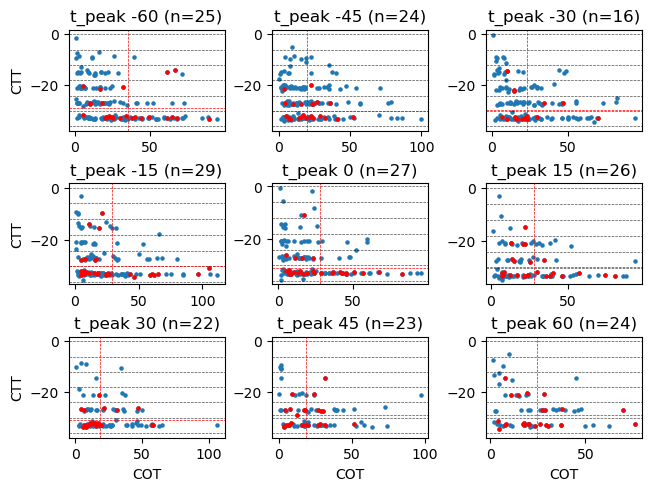

In [203]:
n = len(inds)
nrows = 3
ncols = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, constrained_layout=True)

for i, ind in enumerate(inds):
    row=i//3
    col=i%3
    # print(row,col)
    selected_clouds = bulk_data_df_split[bulk_data_df_split["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds["avg_cot"],selected_clouds["avg_ctt"]-273.15, s=5)
    selected_clouds_filt = bulk_data_filtered[bulk_data_filtered["rel_ind"]==ind]
    axes[row,col].scatter(selected_clouds_filt["avg_cot"],selected_clouds_filt["avg_ctt"]-273.15,color='red',s=5)
    axes[row,col].set_title(f"t_peak {ind*15} (n={len(selected_clouds_filt)})")
    # axes[row,col].set_xscale("log")
    # axes[row,col].set_xlim(0,1e6)
    # axes[row,col].set_ylim(0,20)
    for bound_temp in range(0,-38,-6):
        axes[row,col].axhline(bound_temp,linestyle="--",linewidth=0.5,color="black",alpha=0.7)
    
    axes[row,col].axhline(selected_clouds_filt["avg_ctt"].mean()-273.15,linestyle="--",linewidth=0.5,color="red")
    axes[row,col].axvline(selected_clouds_filt["avg_cot"].mean(),linestyle="--",linewidth=0.5,color="red")

    if col==0:
        axes[row,col].set_ylabel("CTT")
    if row==2:
        axes[row,col].set_xlabel("COT")

plt.show()

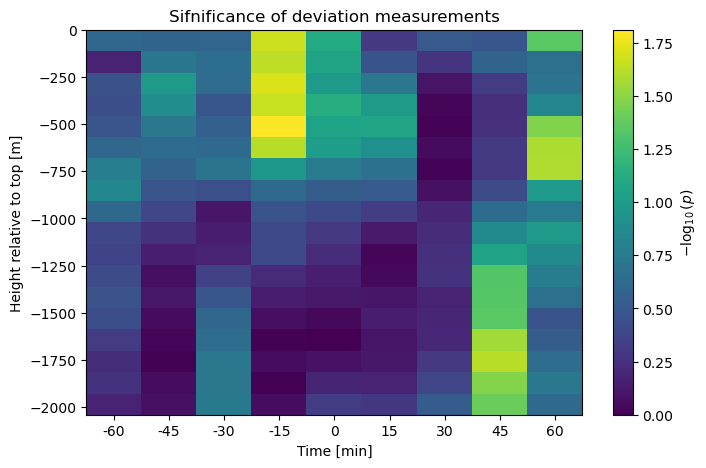

In [204]:
plt.figure(figsize=(8, 5))
sig_map = -np.log10(p_welch_map)
plt.imshow(
    sig_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=0,
)

plt.xticks(inds, inds * 15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")
plt.colorbar(label=r"$-\log_{10}(p)$")
plt.title("Sifnificance of deviation measurements")
plt.show()

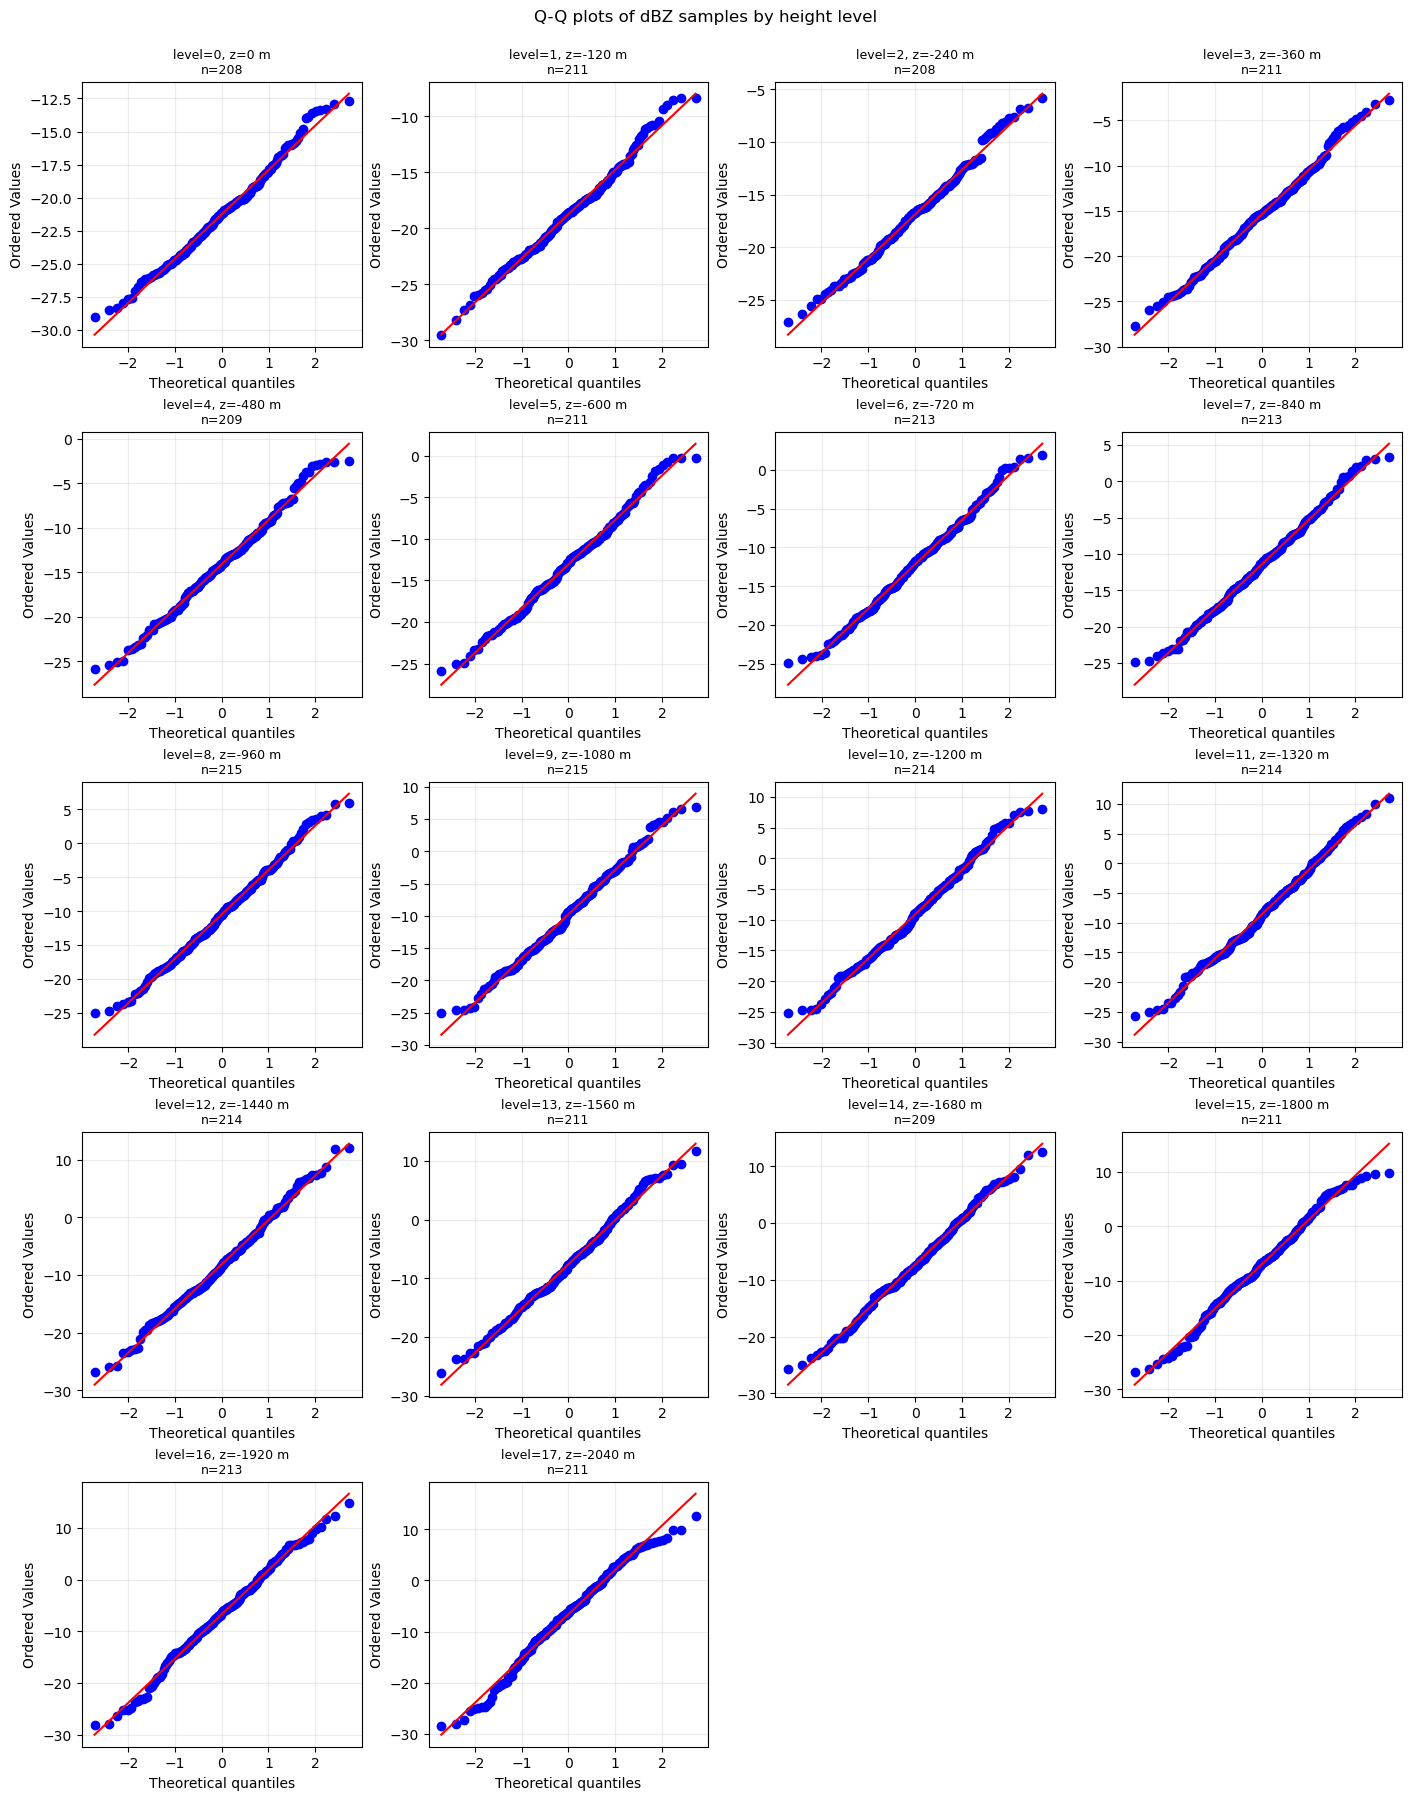

In [205]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

inds = np.arange(ind_range[0], ind_range[1])
n_levels = len(y_levels)

ncols = 4
nrows = int(np.ceil(n_levels / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3.5 * ncols, 3.5 * nrows),
    constrained_layout=True
)

axes = np.ravel(axes)

for level, ax in enumerate(axes[:n_levels]):

    level_samples = []

    for ind in inds:
        dbZ = Z_meas[ind]
        dbZ[~np.isfinite(dbZ)] = np.nan

        x = dbZ[:, level]
        x = x[np.isfinite(x)]
        level_samples.append(x)

    x = np.concatenate(level_samples)
    x=remove_outliers_iqr(x)
    if len(x) > 2:
        stats.probplot(x, dist="norm", plot=ax)

    ax.set_title(
        f"level={level}, z={y_levels[level]:.0f} m\nn={len(x)}",
        fontsize=9
    )
    ax.grid(alpha=0.25)

# Hide unused axes
for ax in axes[n_levels:]:
    ax.axis("off")

fig.suptitle("Q-Q plots of dBZ samples by height level", y=1.02)
plt.show()

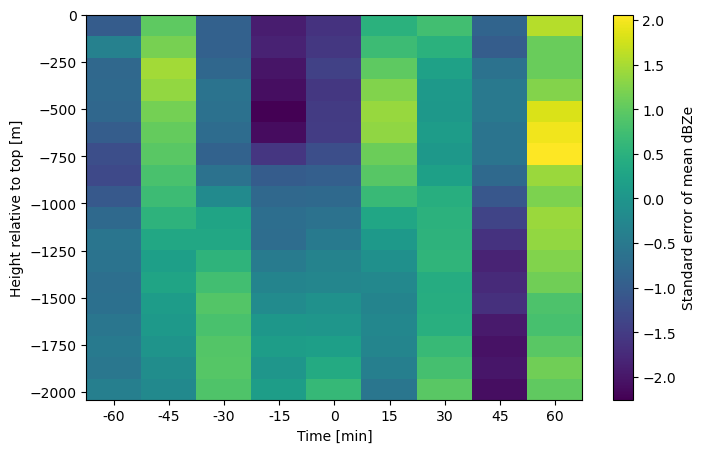

In [206]:
plt.figure(figsize=(8, 5))
plt.imshow(
    dev_vs_others_map / sem_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
)
plt.xticks(inds, inds * 15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")
plt.colorbar(label="Standard error of mean dBZe")
plt.show()

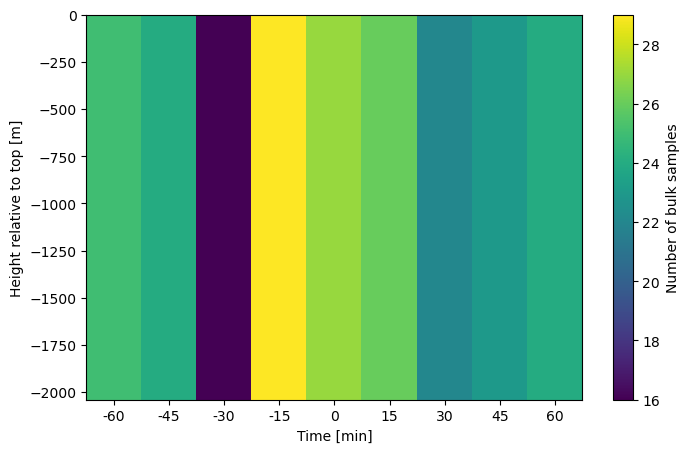

In [207]:
plt.figure(figsize=(8, 5))
plt.imshow(
    n_map,
    aspect="auto",
    origin="upper",
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    
)
plt.xticks(inds, inds * 15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")
plt.colorbar(label="Number of bulk samples")
plt.show()

(array([0., 0., 0., 2., 2., 3., 5., 5., 4., 6., 5., 3., 5., 2., 4., 2., 0.,
        2., 0., 0., 2., 2., 4., 2., 0., 0., 0., 0., 1., 0., 2., 0., 0., 1.,
        0., 0., 0., 1., 1.]),
 array([-0.25,  0.25,  0.75,  1.25,  1.75,  2.25,  2.75,  3.25,  3.75,
         4.25,  4.75,  5.25,  5.75,  6.25,  6.75,  7.25,  7.75,  8.25,
         8.75,  9.25,  9.75, 10.25, 10.75, 11.25, 11.75, 12.25, 12.75,
        13.25, 13.75, 14.25, 14.75, 15.25, 15.75, 16.25, 16.75, 17.25,
        17.75, 18.25, 18.75, 19.25]),
 <BarContainer object of 39 artists>)

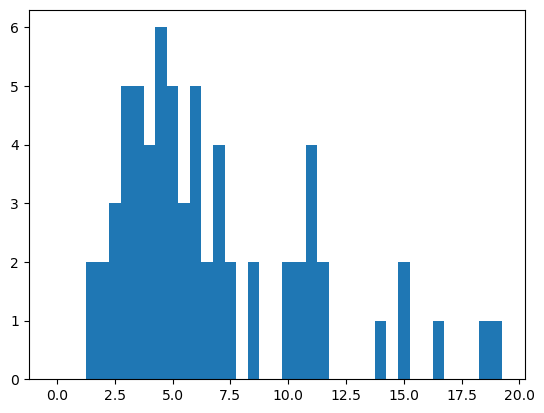

In [208]:
plt.hist(selected_clouds["track_length"]/pd.Timedelta(hours=1),bins=np.arange(0,40)/2-0.25)

# Significance statistics aggregated

In [209]:
from scipy.stats import t
import numpy as np
ind_range = [-8, 9]

inds = np.arange(ind_range[0], ind_range[1])

# Original vertical levels
y_levels = np.asarray(test_row["bulk_level_offset_top_m"])

# New grouped levels using old level indices
level_groups = [
    [0, 1],
    list(range(2, 10)),
    list(range(10, 18)),
]

group_labels = [
    "levels 0-1",
    "levels 2-9",
    "levels 10-17",
]

n_levels = len(level_groups)
n_times = len(inds)

mean_map = np.full((n_levels, n_times), np.nan)
std_map  = np.full((n_levels, n_times), np.nan)
n_map    = np.full((n_levels, n_times), np.nan)

dbZ_grouped_by_ind = {}


def remove_outliers_iqr(x, k=1.5):
    x = x[np.isfinite(x)]

    if len(x) < 4:
        return x

    q1, q3 = np.nanpercentile(x, [25, 75])
    iqr = q3 - q1

    if iqr == 0 or not np.isfinite(iqr):
        return x

    lower = q1 - k * iqr
    upper = q3 + k * iqr

    return x[(x >= lower) & (x <= upper)]


# -------------------------------------------------------------------
# Build grouped maps
# -------------------------------------------------------------------

for col, ind in enumerate(inds):
    dbZ = Z_meas[ind]
    dbZ[~np.isfinite(dbZ)] = np.nan

    # dbZ is assumed to have shape:
    # samples x original_levels
    grouped_dbZ = []

    for group in level_groups:
        vals = dbZ[:, group].ravel()
        vals = vals[np.isfinite(vals)]

        grouped_dbZ.append(vals)

        mean_map[len(grouped_dbZ) - 1, col] = np.nanmean(vals)
        std_map[len(grouped_dbZ) - 1, col]  = np.nanstd(vals, ddof=1)
        n_map[len(grouped_dbZ) - 1, col]    = len(vals)

    dbZ_grouped_by_ind[ind] = grouped_dbZ

sem_map = std_map / np.sqrt(n_map)

In [210]:
p_welch_map = np.full_like(mean_map, np.nan)
dev_vs_others_map = np.full_like(mean_map, np.nan)
effect_size_map = np.full_like(mean_map, np.nan)

n_x_map = np.full_like(mean_map, np.nan)
n_y_raw_map = np.full_like(mean_map, np.nan)
n_y_clean_map = np.full_like(mean_map, np.nan)


for j, ind in enumerate(inds):
    x_groups = dbZ_grouped_by_ind[ind]

    other_inds = [k for k in inds if k != ind]

    for i in range(n_levels):
        x = x_groups[i]
        x = x[np.isfinite(x)]

        # Pool the same grouped level from all other time indices
        y = np.concatenate([
            dbZ_grouped_by_ind[k][i]
            for k in other_inds
        ])

        y = y[np.isfinite(y)]

        n_y_raw = len(y)

        # Remove outliers only from y
        y = remove_outliers_iqr(y, k=1.5)

        if len(x) < 2 or len(y) < 2:
            continue

        mx, my = np.mean(x), np.mean(y)
        vx, vy = np.var(x, ddof=1), np.var(y, ddof=1)
        nx, ny = len(x), len(y)

        dev = mx - my
        se = np.sqrt(vx / nx + vy / ny)

        if se == 0 or not np.isfinite(se):
            continue

        tval = dev / se

        df_num = (vx / nx + vy / ny) ** 2
        df_den = ((vx / nx) ** 2) / (nx - 1) + ((vy / ny) ** 2) / (ny - 1)

        if df_den == 0 or not np.isfinite(df_den):
            continue

        df = df_num / df_den

        p = 2 * t.sf(np.abs(tval), df)

        pooled_sd = np.sqrt((vx + vy) / 2)

        p_welch_map[i, j] = p
        dev_vs_others_map[i, j] = dev

        if pooled_sd > 0 and np.isfinite(pooled_sd):
            effect_size_map[i, j] = dev / pooled_sd

        n_x_map[i, j] = nx
        n_y_raw_map[i, j] = n_y_raw
        n_y_clean_map[i, j] = ny

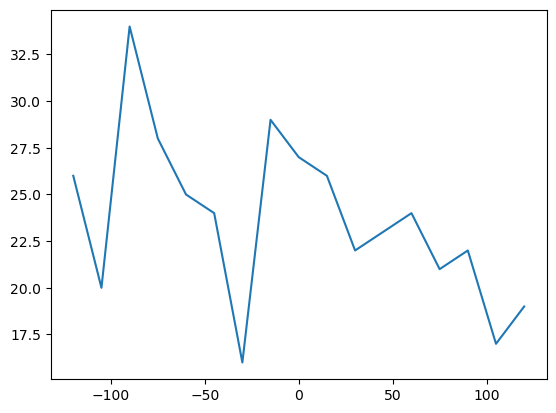

In [211]:
n_meas=[]
for ind in inds:
    n_meas.append(Z_meas[ind].shape[0])
plt.plot(inds*15,n_meas)

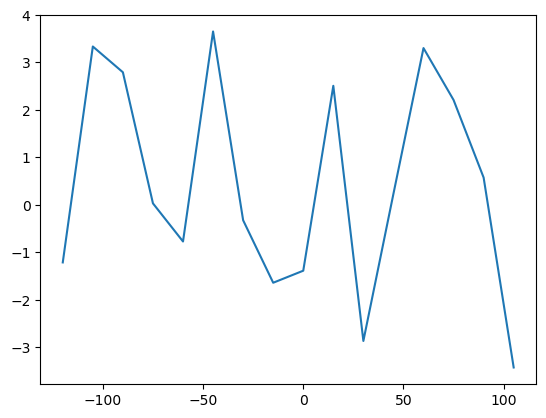

In [212]:
plt.plot(inds[:-1]*15,dev_vs_others_map[1,:-1]+dev_vs_others_map[2,1:])

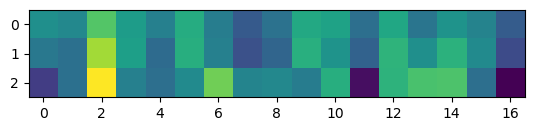

In [213]:
plt.imshow(dev_vs_others_map)


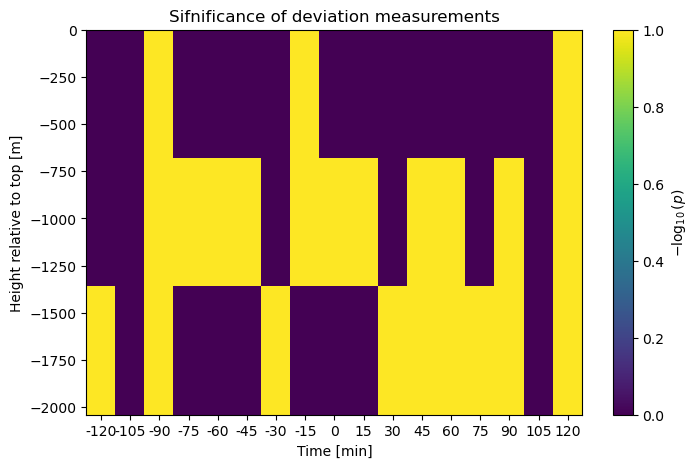

In [214]:
plt.figure(figsize=(8, 5))
sig_map = -np.log10(p_welch_map)
plt.imshow(
    p_welch_map<0.05,
    aspect="auto",
    origin="upper", 
    extent=[
        inds[0] - 0.5,
        inds[-1] + 0.5,
        y_levels[-1],
        y_levels[0],
    ],
    vmin=0,
)

plt.xticks(inds, inds * 15)
plt.xlabel("Time [min]")
plt.ylabel("Height relative to top [m]")
plt.colorbar(label=r"$-\log_{10}(p)$")
plt.title("Sifnificance of deviation measurements")
plt.show()

# Development

In [215]:
mean_iwc_all = np.nanmean(
    np.stack(stats_by_rel_time["mean_iwc_profile"].to_numpy())
)
mean_iwc_all
all_time_mean_by_level = {
    key: np.nanmean(vals)
    for key, vals in level_values.items()
}
all_time_mean_by_level


{(0.0, -120.0): np.float64(8.324503819724818e-06),
 (-120.0, -240.0): np.float64(1.323297057084185e-05),
 (-240.0, -360.0): np.float64(1.8901735823223872e-05),
 (-360.0, -480.0): np.float64(2.4541724752464377e-05),
 (-480.0, -600.0): np.float64(2.959028661510424e-05),
 (-600.0, -720.0): np.float64(3.298799571053632e-05),
 (-720.0, -840.0): np.float64(3.4121618682547705e-05),
 (-840.0, -960.0): np.float64(3.629999201632616e-05),
 (-960.0, -1080.0): np.float64(3.844098209580657e-05),
 (-1080.0, -1200.0): np.float64(4.109927059416114e-05),
 (-1200.0, -1320.0): np.float64(4.374162423878664e-05),
 (-1320.0, -1440.0): np.float64(4.547094620279437e-05),
 (-1440.0, -1560.0): np.float64(4.7354355691696367e-05),
 (-1560.0, -1680.0): np.float64(4.992784006044761e-05),
 (-1680.0, -1800.0): np.float64(5.191403872945384e-05),
 (-1800.0, -1920.0): np.float64(5.525344015409304e-05),
 (-1920.0, -2040.0): np.float64(5.802709478579161e-05),
 (-2040.0, -2160.0): np.float64(6.221942620310142e-05)}